In [1]:
import pandas as pd
import numpy as np
import warnings
from astropy.io import fits
from astropy import modeling
from matplotlib import pyplot as plt
from matplotlib.ticker import (MultipleLocator, AutoMinorLocator)
import matplotlib.colors as mcolors
from astropy.constants import c
from astropy.modeling import models
from astropy import units as u
from specutils.spectra import Spectrum, SpectralRegion
from specutils.fitting import fit_lines, fit_generic_continuum
from specutils.analysis import equivalent_width
from specutils.fitting import find_lines_derivative
from astropy.stats import sigma_clip
from astropy.table import Table
import re
import os
import sys
from PyAstronomy import pyasl
from PyAstronomy.pyasl import fastRotBroad, rotBroad, specAirVacConvert, airtovac2, equidistantInterpolation
from scipy.interpolate import interp1d
from astroquery.gaia import Gaia

import coronagraph as cg
import starfused
from starfused import Photometry

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif"
})

The current archive release 3.15 contains two breaking changes. Please see https://www.cosmos.esa.int/web/gaia/news#GACSrelease315 for details. In case of questions or feedback, please consult the Gaia helpdesk at https://www.cosmos.esa.int/web/gaia/gaia-helpdesk.


In [127]:
'''Params'''

path = '/Users/brooklyngustaf/Desktop/Research/'
df = pd.read_csv(path + 'Brooklyn_NEID_spectra_project/GOLD_WD_binaries_forDon_APOGEE_GAIA_TIC_2MASS_StarHorse.csv',
    dtype={"GAIA": "string"}
)

# tic_id = [316316335]
tic_id = [
63939535,
316316335,
307786701,
168707425,
236017803,
333166853,
257304664,
202364425,
437054608,
16117219,
435238791,
9429166,
387424191,
136954576,
63082902,
344713506,
252791409,
321317174,
309663455,
39718658,
70666120,
291016095,
117249718,
250384503,
8200813,
67907704
]

# FUV and NUV relations

In [128]:
gaia = [
2342601748810281088,
1489443565322051840,
1538007108430585600,
1504269556206093312,
1300333342078030464,
2782712437814936704,
2543685176942889856,
3926980407953775488,
605675811341057280,
898657172940931712,
2813347172521782016,
777481611351426048,
20336704506737536,
1530032659834000000,
668547707285277440,
2539353165552209280,
831779313758465280,
607958633703442816,
932144178250153728,
816865606758305408,
3890324137688150016,
3963353214673355392,
702718707610343296,
2507419263368252928,
754692377439902208,
973009898719861888
]

In [ ]:
# Query using a source name (Gaia, 2MASS, SIMBAD names work)
phot = Photometry.query(
    name="Gaia DR3 831779313758465280",
    filters=['GALEX'],
    radius=1  # arcseconds
)
print(phot)

In [ ]:
results = []

for gaia_id in gaia:
    try:
        phot = Photometry.query(name=f"Gaia DR3 {gaia_id}", filters=["GALEX"], radius=1)
        phot_df = phot.to_pandas() if hasattr(phot, "to_pandas") else pd.DataFrame(phot)

        row = {"Gaia DR3": str(gaia_id)}

        for band in ["FUV", "NUV"]:
            matches = phot_df[phot_df["sed_filter"].astype(str).str.contains(
                f"GALEX:{band}", case=False, na=False
            )]

            if not matches.empty:
                match = matches.iloc[0]
                row[f"{band} flux"] = match["sed_flux"]
                row[f"{band} flux error"] = match["sed_eflux"]
            else:
                row[f"{band} flux"] = float("nan")
                row[f"{band} flux error"] = float("nan")

        results.append(row)

    except Exception as e:
        print(f"Query failed for {gaia_id}: {e}")
        results.append({
            "Gaia DR3": str(gaia_id),
            "FUV flux": float("nan"),
            "FUV flux error": float("nan"),
            "NUV flux": float("nan"),
            "NUV flux error": float("nan")
        })

galex_df = pd.DataFrame(results)
print(galex_df)

In [ ]:
galex_results = []
for gaia_id in gaia:    
    # Query using a source name (Gaia, 2MASS, SIMBAD names work)
    phot = Photometry.query(
        name="Gaia DR3 2342601748810281088",
        filters=['GALEX'],
        radius=1  # arcseconds
    )
# print(phot)

In [ ]:
def galex_fuv_flux_to_mag(flux):
    """
    Converts GALEX FUV flux density (erg/s/cm^2/Angstrom) to AB magnitude.
    
    Parameters:
    flux (float or array-like): Flux density in erg s^-1 cm^-2 Angstrom^-1
    
    Returns:
    float or array-like: FUV AB magnitude
    """
    # GALEX FUV zero-point and calibration factor
    fuv_zero_point = 18.82
    fuv_flux_factor = 1.40e-15
    
    # Calculate magnitude
    magnitude = -2.5 * np.log10(flux / fuv_flux_factor) + fuv_zero_point
    return magnitude

In [ ]:
mag = galex_fuv_flux_to_mag(4.629230e-16)
print(f"{mag:.3f}")

In [403]:
mwo_data = pd.read_csv('/Users/brooklyngustaf/Desktop/Research/mwo_simbad_all.txt', sep='\t')
s_index_mwo = np.array(mwo_data["median_s_index"].to_numpy())
distance_pc_mwo = np.array(mwo_data["distance_pc"].to_numpy())
b_mwo = np.array(mwo_data["B"].to_numpy())
v_mwo = np.array(mwo_data["V"].to_numpy())
v_abs_mwo = v_mwo - 5 * np.log10(distance_pc_mwo) + 5
bv_mwo = b_mwo - v_mwo
fuv_mwo = np.array(mwo_data["FUVmag"].to_numpy())
fuv_abs_mwo = fuv_mwo - 5 * np.log10(distance_pc_mwo) + 5
fuv_v_mwo = fuv_mwo - v_mwo
nuv_ap_mwo = np.array(mwo_data["NUVmag"].to_numpy())
nuv_abs_mwo = nuv_ap_mwo - 5 * np.log10(distance_pc_mwo) + 5
teff_mwo = np.array(mwo_data["Teff"].to_numpy())
# Calculate B-V from Teff
R2_mwo = teff_mwo / 10**4
bv_mwo = 3.964 * R2_mwo**2 - 7.709 * R2_mwo + 3.738
binary_mwo = mwo_data["otypes"].astype("string").str.contains(r"\*\*", na=False).to_numpy()
period_mwo = pd.to_numeric(mwo_data["var_period"], errors="coerce").to_numpy()
sp_type_mwo = mwo_data["sp_type"]

In [404]:
import re
import pandas as pd

def parse_luminosity_class(sptype):
    if pd.isna(sptype):
        return "unknown"

    s = str(sptype).strip().upper().replace(" ", "")

    if not s or s == "NAN":
        return "unknown"

    # Subdwarfs
    if re.search(r"^SD", s):
        return "subdwarf"

    # Intermediate luminosity classes
    if re.search(r"II[-/]III|III[-/]II|II/III|III/II", s):
        return "intermediate_II_III"

    if re.search(r"III[-/]IV|IV[-/]III|III/IV|IV/III", s):
        return "intermediate_III_IV"

    if re.search(r"IV[-/]V|IV/V", s):
        return "intermediate_IV_V"

    # Supergiants: I, Ia, Iab, Ib
    # Negative lookbehind prevents IIIa and IIIb from matching.
    if re.search(r"(?<!I)I(?:AB|A|B)(?![A-Z])", s):
        return "supergiant"

    # Bright giants: class II, excluding class III
    if re.search(r"(?<!I)II(?![I])(?=$|[-/+:?A-Z0-9])", s):
        return "bright_giant"

    # Giants: class III, including IIIa, IIIb, III:
    if "III" in s:
        return "giant"

    # Subgiants
    if "IV" in s:
        return "subgiant"

    # Main sequence
    if "V" in s:
        return "ms"

    return "unknown"


def infer_luminosity_class(teff, logg):
    if pd.isna(teff) or pd.isna(logg):
        return "unknown"

    if logg >= 4.2:
        return "ms_candidate"
    elif logg >= 3.8:
        return "ms_subgiant_ambiguous"
    elif logg >= 3.0:
        return "subgiant_candidate"
    elif logg >= 2.0:
        return "giant_candidate"
    elif logg >= 1.0:
        return "bright_giant_candidate"
    else:
        return "supergiant_candidate"
    

mwo_data["luminosity_class"] = mwo_data["sp_type"].apply(parse_luminosity_class)

print(mwo_data["luminosity_class"].value_counts(dropna=False))

luminosity_class
ms                     467
giant                  357
unknown                131
subgiant                47
intermediate_II_III     24
intermediate_III_IV     19
intermediate_IV_V       17
bright_giant            12
supergiant               6
subdwarf                 1
Name: count, dtype: int64


In [405]:
mwo_data["inferred_luminosity_class"] = mwo_data.apply(
    lambda row: infer_luminosity_class(row["Teff"], row["log_g"])
    if row["luminosity_class"] == "unknown"
    else row["luminosity_class"],
    axis=1
)

In [406]:
print(
    mwo_data.loc[
        mwo_data["luminosity_class"].isin(
            ["unknown", "intermediate_III_IV", "intermediate_IV_V"]
        ),
        ["sp_type", "otype", "luminosity_class", "inferred_luminosity_class", "Teff", "log_g"]
    ].drop_duplicates().sort_values("sp_type").to_string(index=False)
)

     sp_type otype    luminosity_class inferred_luminosity_class   Teff  log_g
          A3     *             unknown     ms_subgiant_ambiguous 7893.0 4.0110
    A3mA6-A8     *             unknown                   unknown    NaN    NaN
          F5   PM*             unknown              ms_candidate 6012.0 4.5990
          F5   PM*             unknown     ms_subgiant_ambiguous 6099.0 4.1900
          F5     *             unknown              ms_candidate 6398.0 4.3400
          F5   Em*             unknown              ms_candidate 6236.0 4.3350
          F5     *             unknown              ms_candidate 6135.0 4.4100
          F5   PM*             unknown                   unknown 6453.0    NaN
          F5   SB*             unknown              ms_candidate 6264.0 4.2800
          F5   PM*             unknown                   unknown 6043.0    NaN
          F5   PM*             unknown                   unknown 6408.0    NaN
    F5III/IV   SB* intermediate_III_IV       interme

In [407]:
candidate_to_class = {
    "ms_candidate": "ms",
    "subgiant_candidate": "subgiant",
    "giant_candidate": "giant"
}

mwo_data["mittag_luminosity_class"] = (
    mwo_data["inferred_luminosity_class"]
    .replace(candidate_to_class)
)

In [408]:
def mittag_smw_to_rhk(S, bv, luminosity_class):
    """
    Convert Mount Wilson S-index to log R'_HK using the
    Mittag et al. (2013) class-dependent flux relations.

    Implemented classes:
        ms, subgiant, giant

    Other classes and unsupported B-V ranges return NaN.

    Parameters
    ----------
    S : array-like
        Mount Wilson S-index.
    bv : array-like
        B-V color.
    luminosity_class : array-like
        Values such as 'ms', 'subgiant', 'giant'.

    Returns
    -------
    ndarray
        log10(R'_HK), with NaN for unsupported inputs.
    """
    S, bv, lc = np.broadcast_arrays(
        np.asarray(S, dtype=float),
        np.asarray(bv, dtype=float),
        np.asarray(luminosity_class, dtype=str)
    )

    lc = np.char.lower(np.char.strip(lc))

    # Start with unsupported values as NaN
    log_fhk = np.full(S.shape, np.nan)
    log_fhk_phot = np.full(S.shape, np.nan)

    valid_s = np.isfinite(S) & (S > 0)
    valid_bv = np.isfinite(bv)

    # Main sequence: 0.44 <= B-V < 1.60
    m = valid_s & valid_bv & (lc == "ms") & (bv >= 0.44) & (bv < 1.28)
    log_fhk[m] = np.log10(S[m]) + 8.25 - 1.67 * bv[m]
    log_fhk_phot[m] = 7.49 - 2.06 * bv[m]

    m = valid_s & valid_bv & (lc == "ms") & (bv >= 1.28) & (bv < 1.60)
    log_fhk[m] = np.log10(S[m]) + 8.25 - 1.67 * bv[m]
    log_fhk_phot[m] = 6.19 - 1.04 * bv[m]

    # Subgiants: 0.44 <= B-V <= 1.10
    m = valid_s & valid_bv & (lc == "subgiant") & (bv >= 0.44) & (bv <= 1.10)
    log_fhk[m] = np.log10(S[m]) + 8.25 - 1.67 * bv[m]
    log_fhk_phot[m] = 7.57 - 2.25 * bv[m]

    # Giants: 0.76 <= B-V <= 1.18
    m = valid_s & valid_bv & (lc == "giant") & (bv >= 0.76) & (bv <= 1.18)
    log_fhk[m] = np.log10(S[m]) + 8.33 - 1.79 * bv[m]
    log_fhk_phot[m] = 7.61 - 2.37 * bv[m]

    # Surface fluxes
    fhk = 10**log_fhk
    fhk_phot = 10**log_fhk_phot

    # Mittag et al. Teff(B-V) relation
    log_teff = 3.981 - 0.4728*bv + 0.2434*bv**2 - 0.0620*bv**3
    teff = 10**log_teff

    # Stefan-Boltzmann constant in cgs units
    sigma = 5.670374419e-5  # erg cm^-2 s^-1 K^-4

    rhk_prime = (fhk - fhk_phot) / (sigma * teff**4)

    # Require positive, finite chromospheric flux
    valid = (
        np.isfinite(rhk_prime)
        & (rhk_prime > 0)
        & np.isfinite(fhk)
        & np.isfinite(fhk_phot)
    )

    log_rhk_prime = np.full(S.shape, np.nan)
    log_rhk_prime[valid] = np.log10(rhk_prime[valid])

    return log_rhk_prime

def mittag_conversion_status(S, bv, lc):
    if pd.isna(S) or S <= 0:
        return "invalid S-index"

    if pd.isna(bv):
        return "missing B-V"

    if lc == "ms":
        if 0.44 <= bv < 1.60:
            return "check flux subtraction"
        return "B-V outside MS range"

    if lc == "subgiant":
        if 0.44 <= bv <= 1.10:
            return "check flux subtraction"
        return "B-V outside subgiant range"

    if lc == "giant":
        if 0.76 <= bv <= 1.18:
            return "check flux subtraction"
        return "B-V outside giant range"

    return "unsupported luminosity class"

In [409]:
mwo_data["logRHK_mittag"] = mittag_smw_to_rhk(
    S=s_index_mwo,
    bv=bv_mwo,
    luminosity_class=mwo_data["mittag_luminosity_class"]
)

In [411]:
print(mwo_data["logRHK_mittag"].notna().sum(), "converted")
print(mwo_data["logRHK_mittag"].isna().sum(), "not converted")

print(
    mwo_data.groupby("mittag_luminosity_class")["logRHK_mittag"]
    .agg(["count", "min", "median", "max"])
)

762 converted
319 not converted
                         count       min    median       max
mittag_luminosity_class                                     
bright_giant                 0       NaN       NaN       NaN
bright_giant_candidate       0       NaN       NaN       NaN
giant                      252 -5.456115 -4.660902 -3.717882
intermediate_III_IV          0       NaN       NaN       NaN
intermediate_II_III          0       NaN       NaN       NaN
intermediate_IV_V            0       NaN       NaN       NaN
ms                         467 -5.135405 -4.503955 -2.992029
ms_subgiant_ambiguous        0       NaN       NaN       NaN
subdwarf                     0       NaN       NaN       NaN
subgiant                    43 -5.274198 -4.554926 -3.759363
supergiant                   0       NaN       NaN       NaN
unknown                      0       NaN       NaN       NaN


In [413]:
unconverted = mwo_data.loc[
    mwo_data["logRHK_mittag"].isna(),
    ["sp_type", "otype", "median_s_index", "mittag_luminosity_class"]
]

print(unconverted.to_string(index=False))

             sp_type otype  median_s_index mittag_luminosity_class
               M4.0V   BY*         6.14880                      ms
               M3.5V   PM*         4.43100                      ms
          K2+IVeFe-1   RS*         2.00120                subgiant
                 NaN   PM*         1.95580                 unknown
                 NaN   PM*         1.92860                 unknown
                 M2V   PM*         1.91215                      ms
               K2III   RS*         1.89957                   giant
               M1.5V   PM*         1.86010                      ms
               G/K:e   BY*         1.83090                 unknown
                 K7V   PM*         1.74940                      ms
               M0.5V   PM*         1.69760                      ms
                 K6V   PM*         1.62285                      ms
                 K6V   PM*         1.62280                      ms
                 K5V   PM*         1.56230                    

In [414]:
mwo_data["conversion_status"] = [
    mittag_conversion_status(S, bv, lc)
    for S, bv, lc in zip(
        mwo_data["median_s_index"],
        bv_mwo,
        mwo_data["mittag_luminosity_class"]
    )
]

print(mwo_data["conversion_status"].value_counts())

conversion_status
check flux subtraction          762
missing B-V                     120
unsupported luminosity class    102
B-V outside giant range          68
B-V outside MS range             25
B-V outside subgiant range        4
Name: count, dtype: int64


In [415]:
print(
    mwo_data.loc[
        mwo_data["logRHK_mittag"].isna(),
        ["sp_type", "otype", "median_s_index",
         "mittag_luminosity_class", "conversion_status"]
    ].to_string(index=False)
)

             sp_type otype  median_s_index mittag_luminosity_class            conversion_status
               M4.0V   BY*         6.14880                      ms         B-V outside MS range
               M3.5V   PM*         4.43100                      ms         B-V outside MS range
          K2+IVeFe-1   RS*         2.00120                subgiant                  missing B-V
                 NaN   PM*         1.95580                 unknown                  missing B-V
                 NaN   PM*         1.92860                 unknown                  missing B-V
                 M2V   PM*         1.91215                      ms                  missing B-V
               K2III   RS*         1.89957                   giant                  missing B-V
               M1.5V   PM*         1.86010                      ms                  missing B-V
               G/K:e   BY*         1.83090                 unknown                  missing B-V
                 K7V   PM*         1.749

In [416]:
logrhk_mittag = mwo_data["logRHK_mittag"]

In [435]:
def classify_mwo_system(otypes):
    if pd.isna(otypes):
        return "unknown"

    types = {x.strip() for x in str(otypes).split("|")}

    if "**" in types:
        return "binary"
    elif "*" in types:
        return "single"
    else:
        return "unknown"

mwo_data["system_type"] = mwo_data["otypes"].apply(classify_mwo_system)

In [357]:
log_rhk_prime_list = []
for i in range(len(s_index_mwo)):   
    # Initialize the conversion tool
    smw_converter = pyasl.SMW_RHK()

    # Provide the median S-index and the star's B-V color
    s_median = s_index_mwo[i]  # Example solar-like S-index
    b_v_color = bv_mwo[i]  # Example solar B-V color
    t_eff = teff_mwo[i]  # Example solar effective temperature

    # Calculate R_HK prime
    r_hk_prime, r_hk, c_cf, _, _, r_phot = smw_converter.SMWtoRHK(
        S=s_median, bv=b_v_color, lc="ms", Teff=t_eff
    )

    log_rhk_prime = np.log10(r_hk_prime)
    log_rhk_prime_list.append(log_rhk_prime)

log_rhk_prime = np.array(log_rhk_prime_list)
print(log_rhk_prime)


--------------------
| PyA User warning |
--------------------
What happened?
    Noyes et al. 1984 give a validity range of 0.44 < B-V < 0.82 for the photospheric correction. However, the authors use it for B-V > 0.82, where it quickly decreases.

--------------------
| PyA User warning |
--------------------
What happened?
    Noyes et al. 1984 give a validity range of 0.44 < B-V < 0.82 for the photospheric correction. However, the authors use it for B-V > 0.82, where it quickly decreases.

--------------------
| PyA User warning |
--------------------
What happened?
    Noyes et al. 1984 give a validity range of 0.44 < B-V < 0.82 for the photospheric correction. However, the authors use it for B-V > 0.82, where it quickly decreases.

--------------------
| PyA User warning |
--------------------
What happened?
    Noyes et al. 1984 give a validity range of 0.44 < B-V < 0.82 for the photospheric correction. However, the authors use it for B-V > 0.82, where it quickly decreases.

----

/var/folders/l4/_mvnx6k155979tth3g7sqpmr0000gn/T/ipykernel_76955/1292968057.py:16: RuntimeWarning: invalid value encountered in log10
  log_rhk_prime = np.log10(r_hk_prime)


In [181]:
import pandas as pd
import numpy as np
from astroquery.gaia import Gaia

# Load your CSV
FUV_systems = pd.read_csv("/Users/brooklyngustaf/Desktop/Research/FUV_systems.csv")

# Extract numeric Gaia DR3 source IDs
FUV_systems["gaia_source_id"] = pd.to_numeric(
    FUV_systems["source_id"].astype(str).str.extract(r"Gaia DR3\s+(\d+)")[0],
    errors="coerce"
).astype("Int64")

# Query Gaia DR3 in batches
source_ids = FUV_systems["gaia_source_id"].dropna().astype("int64").unique()
batch_size = 500
results = []

for i in range(0, len(source_ids), batch_size):
    batch = source_ids[i:i + batch_size]
    ids = ",".join(map(str, batch))

    query = f"""
    SELECT source_id, phot_g_mean_mag, phot_bp_mean_mag, phot_rp_mean_mag
    FROM gaiadr3.gaia_source
    WHERE source_id IN ({ids})
    """

    job = Gaia.launch_job_async(query)
    results.append(job.get_results().to_pandas())

gaia_phot = pd.concat(results, ignore_index=True).drop_duplicates("source_id")

# Calculate estimated Johnson V
c = gaia_phot["phot_bp_mean_mag"] - gaia_phot["phot_rp_mean_mag"]

gaia_phot["V_Gaia"] = (
    gaia_phot["phot_g_mean_mag"]
    + 0.02704 - 0.01424*c + 0.21560*c**2 - 0.01426*c**3
)

# Index Gaia photometry by source ID
gaia_phot["source_id"] = gaia_phot["source_id"].astype("Int64")
gaia_phot = gaia_phot.set_index("source_id")

FUV_systems["gaia_source_id"] = FUV_systems["gaia_source_id"].astype("Int64")

# Map Gaia photometry onto the existing dataframe
for col in ["phot_g_mean_mag", "phot_bp_mean_mag", "phot_rp_mean_mag", "V_Gaia"]:
    FUV_systems[col] = FUV_systems["gaia_source_id"].map(gaia_phot[col])

# Fill existing V_mag values with Gaia-derived magnitudes where available
FUV_systems["V_mag"] = FUV_systems["V_Gaia"].combine_first(FUV_systems["V_mag"])

# Calculate B-V from Teff
R2 = FUV_systems["teff"] / 10**4

FUV_systems["B-V resolved"] = 3.964 * R2**2 - 7.709 * R2 + 3.738

# Save updated CSV
FUV_systems.to_csv(
    "/Users/brooklyngustaf/Desktop/Research/FUV_systems.csv",
    index=False
)

INFO: Query finished. [astroquery.utils.tap.core]


In [459]:
# Extract FUV_systems data
# FUV_data = FUV_systems[["B-V resolved", "FUV_mag", "V_mag", "logrRprimehk"]]
bv_yu = FUV_systems["B-V resolved"].to_numpy()
fuv_v_yu = FUV_systems["FUV_mag"].to_numpy() - FUV_systems["V_mag"].to_numpy()
# nuv_v_yu = FUV_systems["NUV_mag"].to_numpy() - FUV_systems["V_mag"].to_numpy() # csv does not contain NUV mag data
logrhk_yu = FUV_systems["logrRprimehk"].to_numpy()
sb2_yu = FUV_systems["type"].astype("string").str.contains("SB2", case=False, na=False).to_numpy()

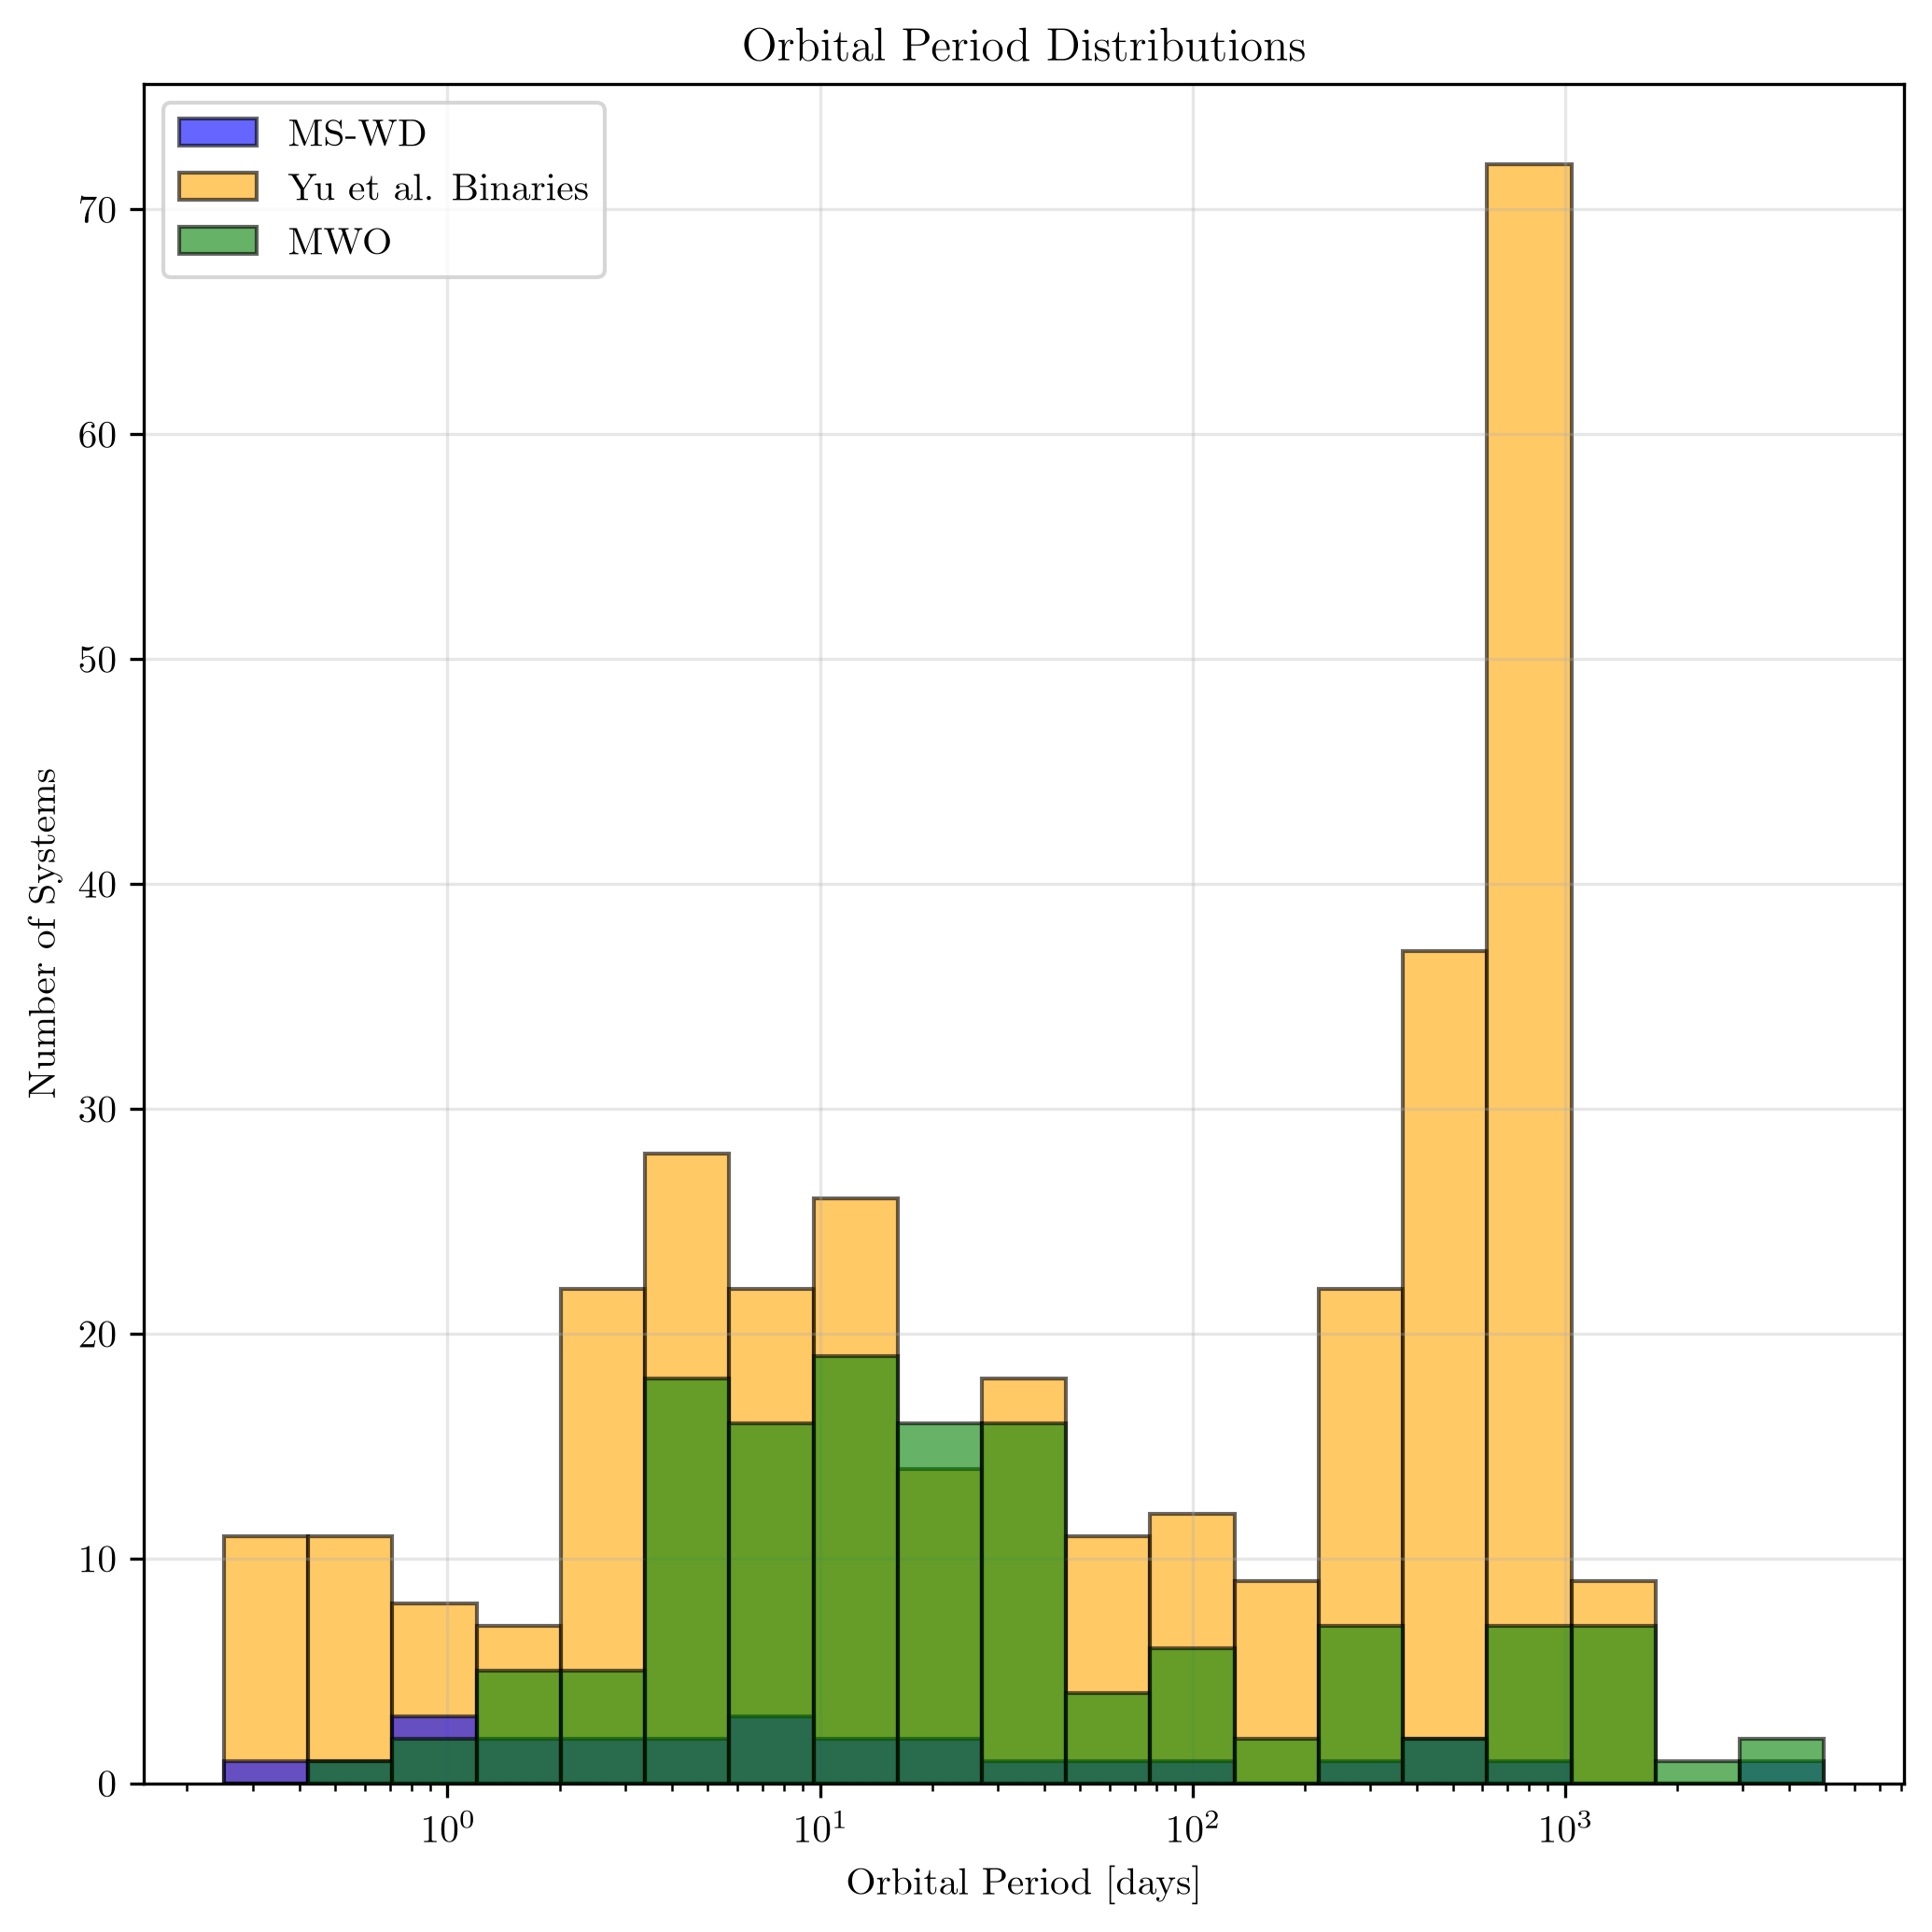

In [463]:
# Extract orbital periods and remove invalid values
period_msw = pd.to_numeric(MSWD_df["Period [days]"], errors="coerce").dropna()
period_fuv = pd.to_numeric(FUV_systems["period"], errors="coerce").dropna()

# Keep only positive orbital periods
period_msw = period_msw[period_msw > 0]
period_fuv = period_fuv[period_fuv > 0]

# Plot histogram
fig, ax = plt.subplots(figsize=(7, 7), dpi=300, sharex=True, sharey=False)

bins = np.logspace(
    np.log10(min(period_msw.min(), period_fuv.min(), period_mwo.min())),
    np.log10(max(period_msw.max(), period_fuv.max(), period_mwo.max())),
    20
)

ax.hist(period_msw, bins=bins, alpha=0.6, label="MS-WD", color="blue", edgecolor="black", zorder=2)
ax.hist(period_fuv, bins=bins, alpha=0.6, label="Yu et al. Binaries", color="orange", edgecolor="black", zorder=1)
ax.hist(period_mwo, bins=bins, alpha=0.6, label="MWO", color="green", edgecolor="black", zorder=3)

# ax.set_ylim(0, 8)
ax.set_xscale("log")
ax.set_xlabel("Orbital Period [days]")
ax.set_ylabel("Number of Systems")
ax.set_title("Orbital Period Distributions")
ax.legend(loc="upper left")
# ax.legend(loc="upper left")
# ax.legend(loc="upper left")
ax.grid(alpha=0.3)
# ax.grid(alpha=0.3)
# ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [464]:
period_msw = pd.to_numeric(MSWD_df["Period [days]"], errors="coerce")
period_yu = pd.to_numeric(FUV_systems["period"], errors="coerce")

all_periods = pd.concat([period_msw, period_yu, period_msw])
all_periods = all_periods[np.isfinite(all_periods) & (all_periods > 0)]

period_min = all_periods.min()
period_max = all_periods.max()

# # Use FUV_systems to define the color scale
# valid_yu_periods = period_yu[np.isfinite(period_yu) & (period_yu > 0)]

# period_min = valid_yu_periods.min()
# period_max = valid_yu_periods.max()

from matplotlib.colors import LogNorm

period_cmap = plt.cm.plasma
period_norm = LogNorm(vmin=period_min, vmax=period_max)

gray = (0.5, 0.5, 0.5, 1.0)

colors_msw = np.array([
    period_cmap(period_norm(p)) if pd.notna(p) and p > 0 else gray
    for p in period_msw
])

colors_yu = np.array([
    period_cmap(period_norm(p)) if pd.notna(p) and p > 0 else gray
    for p in period_yu
])

colors_mwo = np.array([
    period_cmap(period_norm(p)) if np.isfinite(p) and p > 0 else gray
    for p in period_mwo
])

MWO MS stars: 321
Yu stars: 349
Total fitting sample: 670
$\log R'_{\rm HK} < -5.0$, degree 2: R²=0.144, RMSE=1.149, AICc=18.85, BIC=23.58
$\log R'_{\rm HK} < -5.0$, degree 3: R²=0.151, RMSE=1.144, AICc=21.31, BIC=26.80
$\log R'_{\rm HK} < -5.0$, degree 4: R²=0.152, RMSE=1.144, AICc=24.27, BIC=30.31
$-5.0 \leq \log R'_{\rm HK} < -4.5$, degree 2: R²=0.537, RMSE=0.739, AICc=-134.84, BIC=-121.16
$-5.0 \leq \log R'_{\rm HK} < -4.5$, degree 3: R²=0.557, RMSE=0.723, AICc=-143.14, BIC=-126.09
$-5.0 \leq \log R'_{\rm HK} < -4.5$, degree 4: R²=0.558, RMSE=0.721, AICc=-141.74, BIC=-121.33
$-4.5 \leq \log R'_{\rm HK} < -4.0$, degree 2: R²=0.529, RMSE=0.966, AICc=-13.77, BIC=1.10
$-4.5 \leq \log R'_{\rm HK} < -4.0$, degree 3: R²=0.543, RMSE=0.951, AICc=-21.09, BIC=-2.54
$-4.5 \leq \log R'_{\rm HK} < -4.0$, degree 4: R²=0.544, RMSE=0.951, AICc=-19.43, BIC=2.80
$\log R'_{\rm HK} \geq -4.0$, degree 2: R²=0.794, RMSE=0.906, AICc=-8.46, BIC=0.87
$\log R'_{\rm HK} \geq -4.0$, degree 3: R²=0.802, RMSE=0.

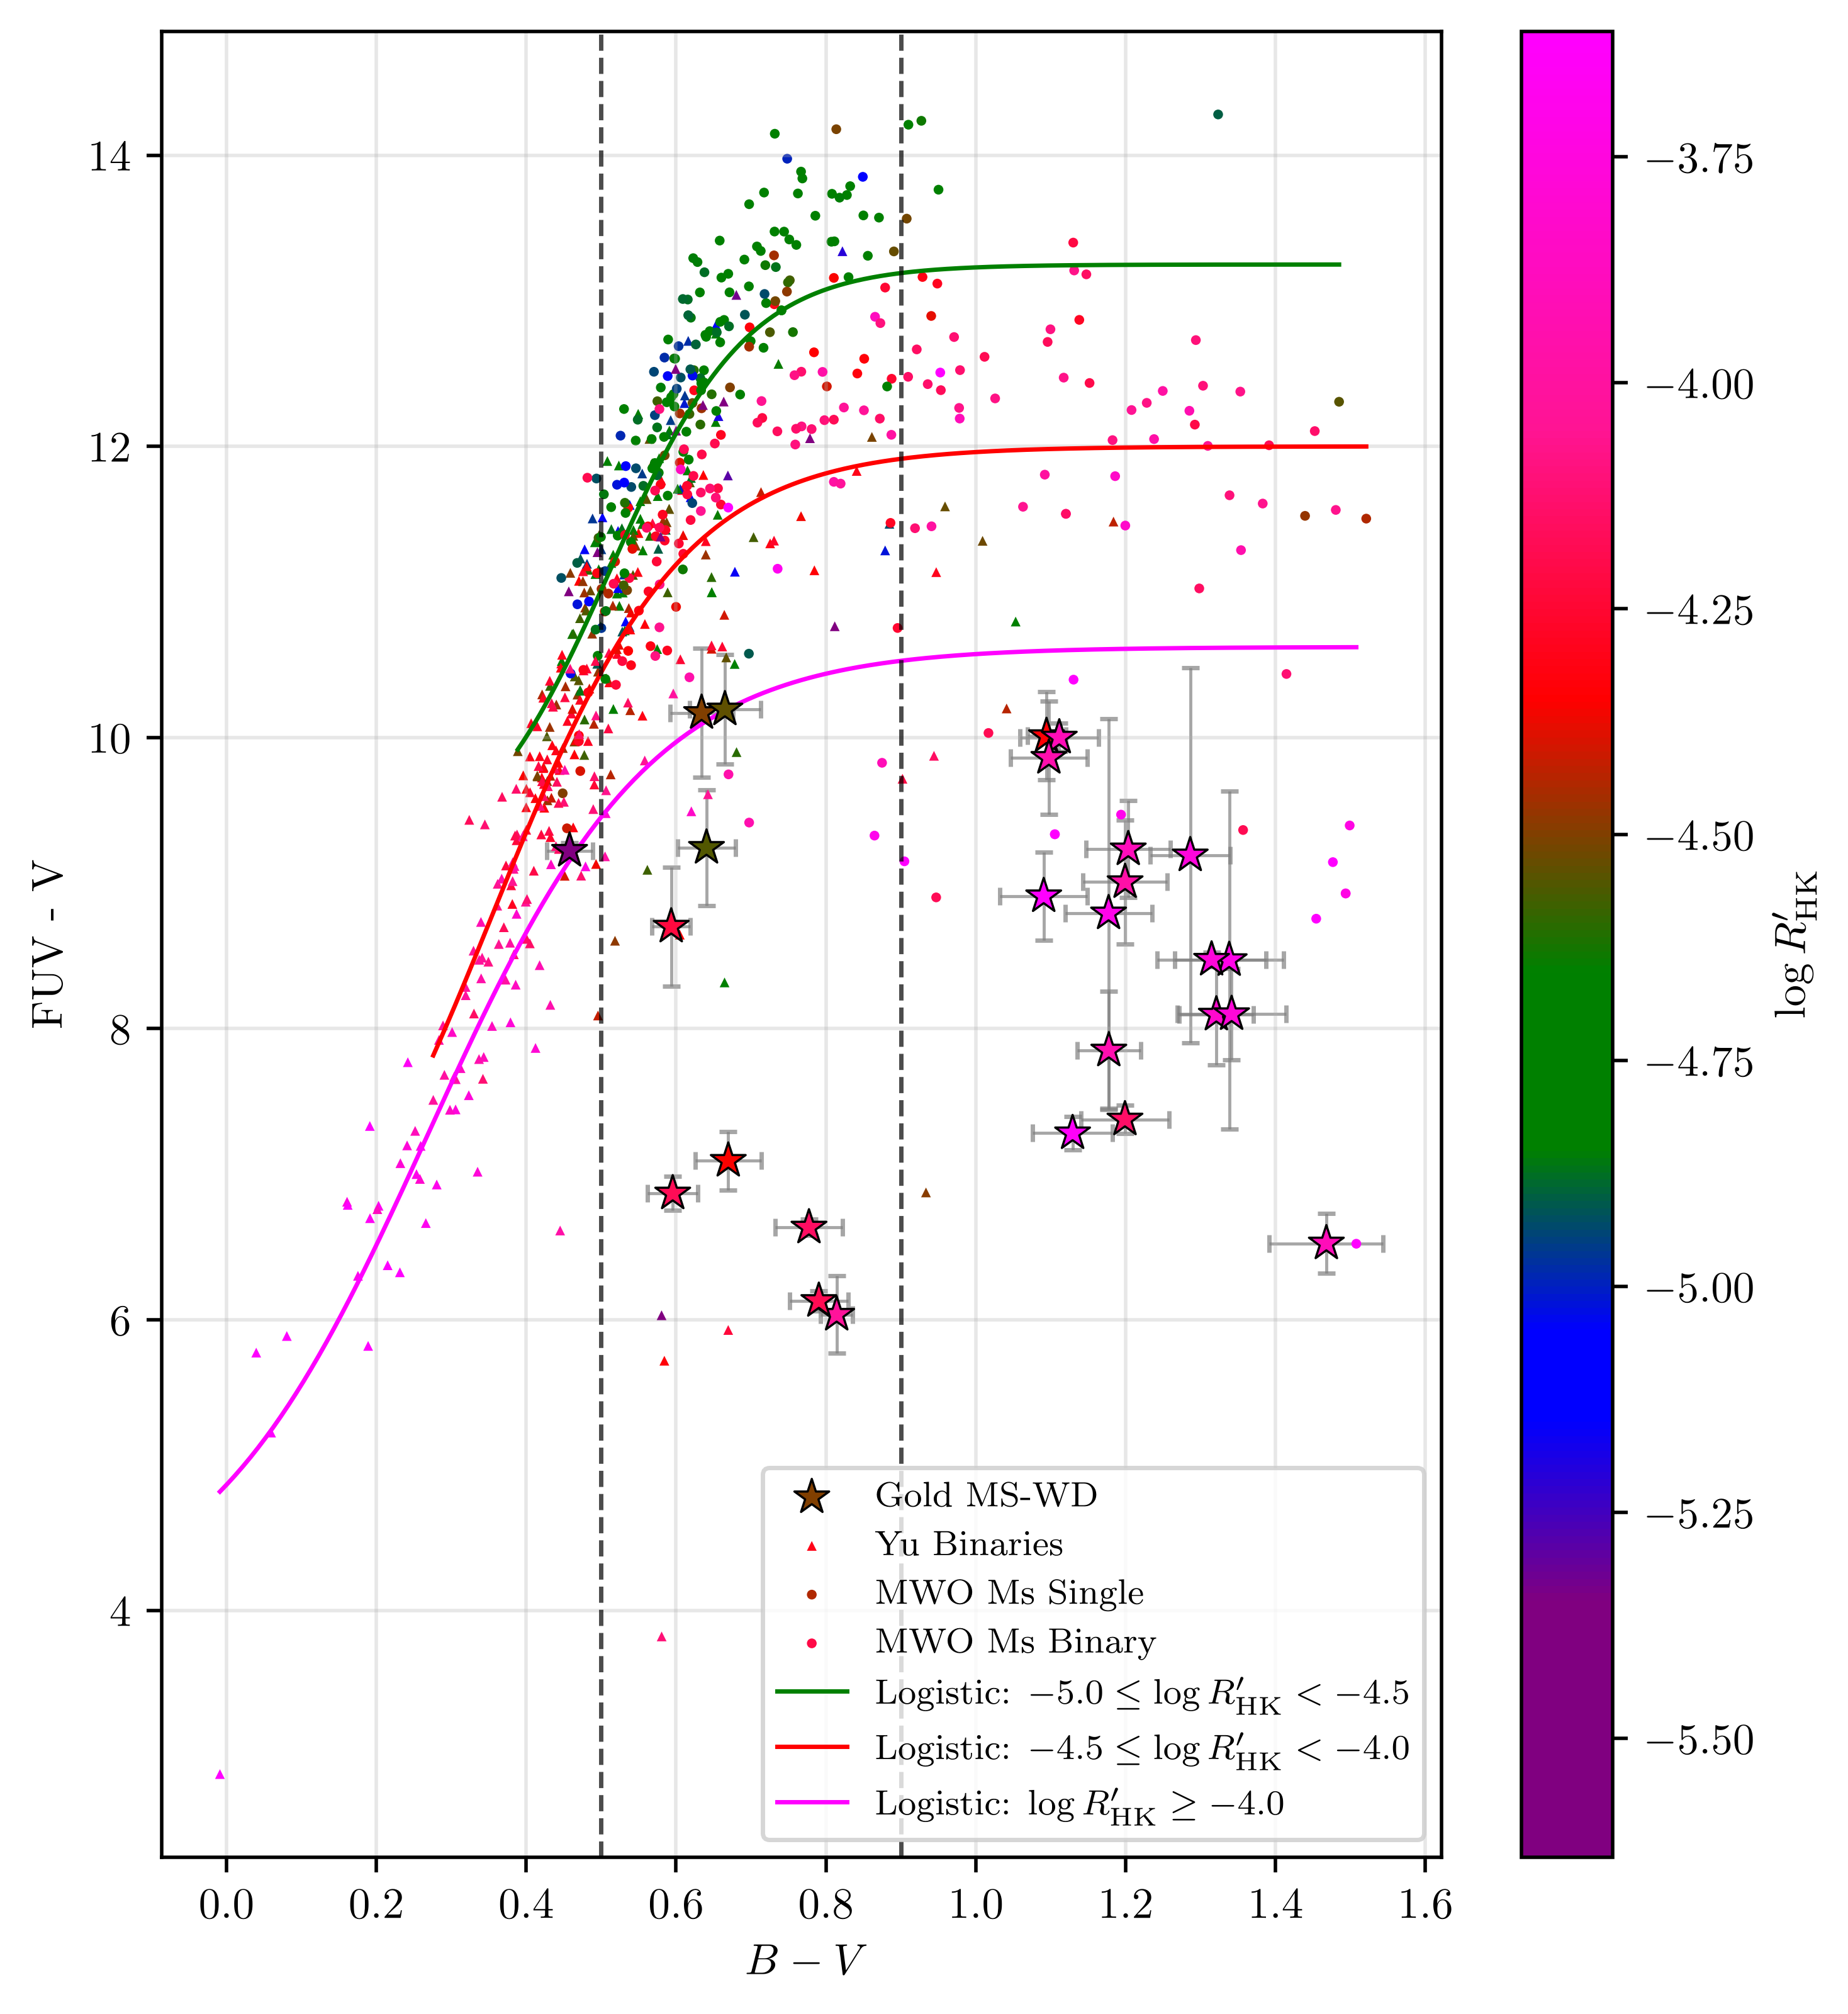

In [492]:
from matplotlib.colors import LinearSegmentedColormap, Normalize

# Load data
path = '/Users/brooklyngustaf/Desktop/Research/Brooklyn_NEID_spectra_project/WDMS2 - WD-MS.csv'
MSWD_df = pd.read_csv(path)
MSWD_df.columns = MSWD_df.columns.str.strip()
MSWD_df["B-V resolved"] = pd.to_numeric(MSWD_df["B-V resolved"], errors="coerce")

# Extract columns
fuv = MSWD_df["FUV obs"]
fuv_err = MSWD_df["FUV obs err"]
fuv2 = MSWD_df["FUV mag (2)"]
fuv_abs_gold = fuv - 5 * np.log10(MSWD_df["Dist [pc]"] / 10)
nuv = MSWD_df["NUV obs"]
v = MSWD_df["v mag"]
v_err = MSWD_df["v err"]
bv = MSWD_df["B-V resolved"]
bv_err = MSWD_df["B-V resolved err"]
logrhk = MSWD_df["logR'_HK (new)"]
teff = MSWD_df["MS Teff"]

# Calculate observed FUV - V and NUV-V
fuv_v = fuv - v
nuv_v = nuv - v
fuv2_v = fuv2 - v

# Propagated FUV - V uncertainty
fuv_v_err = np.sqrt(fuv_err**2 + v_err**2)

fig, ax = plt.subplots(figsize=(6, 6.5), dpi=500)

# B-V range for theoretical curves
AI = np.linspace(0.5, 0.9, 300)

# Fixed V magnitude (set to 0 to plot the conversion offset)
AD = 0

# Representative log R'HK values and curve colors
activity_values = [
    (-3.6, r"$\log R'_{\rm HK} = -3.6$", "magenta", "solid", 0.7),
    (-3.7, None, "magenta", "--", 0.25),
    (-3.8, None, "magenta", "--", 0.25),
    (-3.9, None, "magenta", "--", 0.25),
    (-4.0, None, "magenta", "--", 0.25),
    (-4.1, None, "magenta", "--", 0.25),
    (-4.2, None, "magenta", "--", 0.25),
    # (-4.2, r"$\log R'_{\rm HK} = -4.2$", "magenta"),
    (-4.2, r"$\log R'_{\rm HK} = -4.2$", "red", "solid",0.7),
    # (-4.5, r"$\log R'_{\rm HK} = -4.5$", "red"),
    (-4.5, r"$\log R'_{\rm HK} = -4.5$", "green", "solid", 0.7),
    (-5.0, r"$\log R'_{\rm HK} = -5.0$", "green", "solid", 0.7),
    # (-5.0, r"$\log R'_{\rm HK} = -5.0$", "blue"),
    (-5.2, r"$\log R'_{\rm HK} = -5.2$", "blue", "solid", 0.7),
    # (-5.2, r"$\log R'_{\rm HK} = -5.2$", "purple"),
    (-5.6, r"$\log R'_{\rm HK} = -5.6$", "purple", "solid", 0.7)
]

# Plot Equation (2) curves
for BI, label, color, linestyle, alpha in activity_values:
    x = BI + 4.5
    z = AI - 0.8

    y = (12.30 - 3.95*x - 2.94*x**2
         + 2.22*z - 9.11*z*x - 12.0*z*x**2
         - 17.6*z**2 - 3.9*z**2*x - 24.3*z**2*x**2)

    # ax.plot(AI, y, label=label, color=color, linestyle=linestyle, alpha=alpha)

# Define observed data activity groups
groups = [
    (logrhk > -4.2, "magenta", r"$\log R'_{\rm HK} > -4.2$"),
    ((logrhk >= -4.5) & (logrhk <= -4.2), "red", r"$-4.5 \leq \log R'_{\rm HK} \leq -4.2$"),
    ((logrhk >= -5.0) & (logrhk <= -4.5), "green",
     r"$-5.0 \leq \log R'_{\rm HK} \leq -4.5$"),
    (logrhk < -5.0, "blue", r"$\log R'_{\rm HK} < -5.0$")
]

# # Plot observed stars
# for mask, color, label in groups:
#     valid = mask & bv.notna() & fuv_v.notna() & logrhk.notna()
#     ax.scatter(bv[valid], fuv_v[valid], color=color, s=35, alpha=0.7, label=label)

valid = bv.notna() & fuv_v.notna() & logrhk.notna()
valid_mwo = np.isfinite(bv_mwo) & np.isfinite(fuv_v_mwo) & np.isfinite(logrhk_mittag)
valid_yu = np.isfinite(bv_yu) & np.isfinite(fuv_v_yu) & np.isfinite(logrhk_yu)
vmin = logrhk[valid].min()
vmax = logrhk[valid].max()

# Activity boundaries with sharper color transitions
eps = 0.15

activity_points = [
    vmin,
    -5.2 - eps, -5.2 + eps,
    -5.0 - eps, -5.0 + eps,
    -4.5 - eps, -4.5 + eps,
    -4.2 - eps, -4.2 + eps,
    -3.6, vmax
]

activity_colors = [
    "purple",
    "purple", "blue",
    "blue", "green",
    "green", "red",
    "red", "deeppink",
    "deeppink", "magenta"
]

# Keep points within the data range and sort them
color_stops = sorted(
    [(p, c) for p, c in zip(activity_points, activity_colors) if vmin <= p <= vmax],
    key=lambda item: item[0]
)

# Remove duplicate positions to ensure monotonicity
unique_stops = {}
for p, c in color_stops:
    unique_stops[p] = c

points = list(unique_stops.keys())
colors_at_points = list(unique_stops.values())
positions = [(p - vmin) / (vmax - vmin) for p in points]

cmap = LinearSegmentedColormap.from_list("activity", list(zip(positions, colors_at_points)))
norm = Normalize(vmin=vmin, vmax=vmax)

bad = valid & ((logrhk > -4.2) | (logrhk < -5.2))
bad_mwo = valid_mwo & ((logrhk_mittag > -4.2) | (logrhk_mittag < -5.2))
bad_yu = valid_yu & ((logrhk_yu > -4.2) | (logrhk_yu < -5.2))
bad_yu_sb2 = bad_yu & sb2_yu
bad_yu_other = bad_yu & ~sb2_yu


good = valid & (logrhk >= -5.2) & (logrhk <= -4.2)
good_mwo = valid_mwo & (logrhk_mittag >= -5.2) & (logrhk_mittag <= -4.2)
good_yu = valid_yu & (logrhk_yu >= -5.2) & (logrhk_yu <= -4.2)
good_yu_sb2 = good_yu & sb2_yu
good_yu_other = good_yu & ~sb2_yu

#! Activity Plot
sc = ax.scatter(bv[good], fuv_v[good], c=logrhk[good], edgecolors='black', linewidths=0.5,
                cmap=cmap, norm=norm, s=70, alpha=1, zorder=3, marker='*', label="Gold MS-WD")

ax.scatter(bv[bad], fuv_v[bad], c=logrhk[bad], edgecolors='black', linewidths=0.5,
           cmap=cmap, norm=norm, s=70, alpha=1, zorder=3, marker='*')

# Error bars for Gold MS-WD systems
ax.errorbar(bv, fuv_v, xerr=bv_err, yerr=fuv_v_err, fmt="none", ecolor="gray", elinewidth=0.7, capsize=2, alpha=0.7, zorder=1)

# ax.scatter(bv_mwo[good_mwo], fuv_v_mwo[good_mwo], c=logrhk_mittag[good_mwo], edgecolors='black', linewidths=0.5,
#            cmap=cmap, norm=norm, s=30, alpha=1, zorder=1, marker='s', label="MWO")

# ax.scatter(bv_mwo[bad_mwo], fuv_v_mwo[bad_mwo], c=logrhk_mittag[bad_mwo], edgecolors='black', linewidths=0.5,
#            cmap=cmap, norm=norm, s=30, alpha=1, zorder=2, marker='s', label="")

ax.scatter(bv_yu[good_yu], fuv_v_yu[good_yu], c=logrhk_yu[good_yu], edgecolors='None', linewidths=0.5,
           cmap=cmap, norm=norm, s=5, alpha=1, zorder=1, marker='^', label="Yu Binaries")

ax.scatter(bv_yu[bad_yu], fuv_v_yu[bad_yu], c=logrhk_yu[bad_yu], edgecolors='None', linewidths=0.5,
           cmap=cmap, norm=norm, s=5, alpha=1, zorder=2, marker='^', label="")

# Options: "ms", "giant", "subgiant", "all"
plot_luminosity = "ms"

# MWO marker shapes based on Mittag luminosity classification
mwo_lc = mwo_data["mittag_luminosity_class"].to_numpy()
mwo_system = mwo_data["system_type"].to_numpy()

marker_dict = {
    "ms": "o",
    "giant": "s",
    "subgiant": "p"
}

edge_dict = {
    "single": "None",
    "binary": "None"
}

if plot_luminosity == "all":
    selected_classes = list(marker_dict.keys())
else:
    selected_classes = [plot_luminosity]

for lc in selected_classes:
    for system, edgecolor in edge_dict.items():
        marker = marker_dict[lc]
        lc_mask = mwo_lc == lc
        system_mask = mwo_system == system

        mask_good = good_mwo & lc_mask & system_mask
        mask_bad = bad_mwo & lc_mask & system_mask

        ax.scatter(bv_mwo[mask_good], fuv_v_mwo[mask_good],
                   c=logrhk_mittag[mask_good], edgecolors=edgecolor, linewidths=0.5,
                   cmap=cmap, norm=norm, s=5, alpha=1, zorder=1,
                   marker=marker, label=f"MWO {lc.capitalize()} {system.capitalize()}")

        ax.scatter(bv_mwo[mask_bad], fuv_v_mwo[mask_bad],
                   c=logrhk_mittag[mask_bad], edgecolors=edgecolor, linewidths=0.5,
                   cmap=cmap, norm=norm, s=5, alpha=1, zorder=2,
                   marker=marker)

# mwo_lc = mwo_data["mittag_luminosity_class"].to_numpy()

# marker_dict = {
#     "ms": "o",
#     "giant": "s",
#     "subgiant": "p"
# }

# if plot_luminosity == "all":
#     selected_classes = list(marker_dict.keys())
# else:
#     selected_classes = [plot_luminosity]

# for lc in selected_classes:
#     marker = marker_dict[lc]
#     lc_mask = mwo_lc == lc

#     mask_good = good_mwo & lc_mask
#     mask_bad = bad_mwo & lc_mask

#     ax.scatter(bv_mwo[mask_good], fuv_v_mwo[mask_good],
#                c=logrhk_mittag[mask_good], edgecolors="black", linewidths=0.5,
#                cmap=cmap, norm=norm, s=30, alpha=1, zorder=1,
#                marker=marker, label=f"MWO {lc.capitalize()}")

#     ax.scatter(bv_mwo[mask_bad], fuv_v_mwo[mask_bad],
#                c=logrhk_mittag[mask_bad], edgecolors="black", linewidths=0.5,
#                cmap=cmap, norm=norm, s=30, alpha=1, zorder=2,
#                marker=marker)

# MWO main-sequence stars
ms_mask = valid_mwo & (mwo_lc == "ms")

# Combine MWO MS and all valid Yu data
fit_bv = np.concatenate([bv_mwo[ms_mask], bv_yu[valid_yu]])
fit_fuv_v = np.concatenate([fuv_v_mwo[ms_mask], fuv_v_yu[valid_yu]])
fit_logrhk = np.concatenate([logrhk_mittag[ms_mask], logrhk_yu[valid_yu]])

print(f"MWO MS stars: {ms_mask.sum()}")
print(f"Yu stars: {valid_yu.sum()}")
print(f"Total fitting sample: {len(fit_bv)}")

from sklearn.metrics import r2_score, mean_squared_error

activity_groups = [
    (fit_logrhk < -5.0, "blue", r"$\log R'_{\rm HK} < -5.0$"),
    ((fit_logrhk >= -5.0) & (fit_logrhk < -4.5), "green", r"$-5.0 \leq \log R'_{\rm HK} < -4.5$"),
    ((fit_logrhk >= -4.5) & (fit_logrhk < -4.0), "red", r"$-4.5 \leq \log R'_{\rm HK} < -4.0$"),
    (fit_logrhk >= -4.0, "magenta", r"$\log R'_{\rm HK} \geq -4.0$")
    # (fit_logrhk >= -4.5, "red", r"$\log R'_{\rm HK} \geq -4.5$")
]

fit_results = {}

for mask, color, label in activity_groups:
    x = fit_bv[mask]
    y = fit_fuv_v[mask]

    if len(x) < 6:
        print(f"{label}: Not enough points")
        continue

    fit_results[color] = {}

    for degree in [2, 3, 4]:
        coeffs = np.polyfit(x, y, degree)
        y_pred = np.polyval(coeffs, x)

        residuals = y - y_pred
        rss = np.sum(residuals**2)
        n = len(x)
        k = degree + 2  # Polynomial coefficients + residual variance

        aic = n * np.log(rss / n) + 2 * k
        aicc = aic + (2 * k * (k + 1)) / (n - k - 1) if n > k + 1 else np.nan
        bic = n * np.log(rss / n) + k * np.log(n)

        fit_results[color][degree] = {
            "coeffs": coeffs,
            "r2": r2_score(y, y_pred),
            "rmse": np.sqrt(mean_squared_error(y, y_pred)),
            "aicc": aicc,
            "bic": bic
        }

        print(f"{label}, degree {degree}: R²={r2_score(y, y_pred):.3f}, "
              f"RMSE={np.sqrt(mean_squared_error(y, y_pred)):.3f}, "
              f"AICc={aicc:.2f}, BIC={bic:.2f}")

for mask, color, label in activity_groups:
    if color not in fit_results or 3 not in fit_results[color]:
        continue

    x = fit_bv[mask]
    coeffs = fit_results[color][2]["coeffs"]

    x_fit = np.linspace(x.min(), x.max(), 300)
    y_fit = np.polyval(coeffs, x_fit)

    # ax.plot(x_fit, y_fit, color=color, linestyle="-", linewidth=1,
    #         label=f"Cubic: {label}")

# Log growth curve
from scipy.optimize import curve_fit

def log_growth(x, a, h, c):
    return a * np.log(x - h) + c

log_results = {}

for mask, color, label in activity_groups:
    x = fit_bv[mask]
    y = fit_fuv_v[mask]

    if len(x) < 5:
        continue

    # Ensure the logarithm argument is positive
    h_max = x.min() - 1e-6

    try:
        popt, pcov = curve_fit(
            log_growth, x, y,
            p0=[1, x.min() - 0.1, np.mean(y)],
            bounds=([-np.inf, -np.inf, -np.inf],
                    [np.inf, h_max, np.inf]),
            maxfev=20000
        )

        y_pred = log_growth(x, *popt)
        residuals = y - y_pred

        log_results[color] = {
            "params": popt,
            "r2": r2_score(y, y_pred),
            "rmse": np.sqrt(mean_squared_error(y, y_pred)),
            "residuals": residuals
        }

        print(f"{label}: a={popt[0]:.4f}, h={popt[1]:.4f}, c={popt[2]:.4f}, "
              f"R²={r2_score(y, y_pred):.3f}, "
              f"RMSE={np.sqrt(mean_squared_error(y, y_pred)):.3f}")

    except RuntimeError:
        print(f"{label}: Fit did not converge")

for mask, color, label in activity_groups:
    if color not in log_results:
        continue

    x = fit_bv[mask]
    params = log_results[color]["params"]

    x_fit = np.linspace(x.min(), x.max(), 300)
    y_fit = log_growth(x_fit, *params)

    # ax.plot(x_fit, y_fit, color=color, linestyle="-", linewidth=1,
    #         label=f"Logarithmic: {label}")

from scipy.optimize import curve_fit

def logistic_growth(x, y0, A, k, x0):
    return y0 + A / (1 + np.exp(-k * (x - x0)))

growth_results = {}

for mask, color, label in activity_groups:
    x = fit_bv[mask]
    y = fit_fuv_v[mask]

    if len(x) < 6:
        continue

    p0 = [y.min(), y.max() - y.min(), 5, np.median(x)]

    try:
        popt, pcov = curve_fit(
            logistic_growth, x, y, p0=p0,
            maxfev=30000
        )

        y_pred = logistic_growth(x, *popt)
        residuals = y - y_pred

        growth_results[color] = {
            "params": popt,
            "r2": r2_score(y, y_pred),
            "rmse": np.sqrt(mean_squared_error(y, y_pred))
        }

        print(f"{label}: y0={popt[0]:.3f}, A={popt[1]:.3f}, "
              f"k={popt[2]:.3f}, x0={popt[3]:.3f}, "
              f"R²={r2_score(y, y_pred):.3f}, "
              f"RMSE={np.sqrt(mean_squared_error(y, y_pred)):.3f}")

    except RuntimeError:
        print(f"{label}: Fit did not converge")

for mask, color, label in activity_groups:
    if color not in growth_results:
        continue

    x = fit_bv[mask]
    params = growth_results[color]["params"]

    x_fit = np.linspace(x.min(), x.max(), 300)
    y_fit = logistic_growth(x_fit, *params)

    ax.plot(x_fit, y_fit, color=color, linestyle="-", linewidth=1,
            label=f"Logistic: {label}")

#! Activity Color Bar
cbar = fig.colorbar(sc, ax=ax)
cbar.set_label(r"$\log R'_{\rm HK}$")
# cbar.set_ticks([-5.0, -4.75, -4.5, -4.35, -4.2])


# Shade between activity-region boundaries
shade_regions = [
    (-3.6, -4.2, "magenta", 0.2),
    (-4.2, -4.5, "red", 0.2),
    (-4.5, -5.0, "green", 0.2),
    (-5.0, -5.2, "blue", 0.2),
    (-5.2, -5.6, "purple", 0.2)
]

for r1, r2, color, alpha in shade_regions:
    x1, x2 = r1 + 4.5, r2 + 4.5
    z = AI - 0.8

    y1 = (12.30 - 3.95*x1 - 2.94*x1**2
          + 2.22*z - 9.11*z*x1 - 12.0*z*x1**2
          - 17.6*z**2 - 3.9*z**2*x1 - 24.3*z**2*x1**2)

    y2 = (12.30 - 3.95*x2 - 2.94*x2**2
          + 2.22*z - 9.11*z*x2 - 12.0*z*x2**2
          - 17.6*z**2 - 3.9*z**2*x2 - 24.3*z**2*x2**2)

    # ax.fill_between(AI, y1, y2, color=color, alpha=alpha, zorder=0)

plt.axvline(x=0.5, color='black', linestyle='--', linewidth=1, alpha=0.7)
plt.axvline(x=0.9, color='black', linestyle='--', linewidth=1, alpha=0.7)

ax.set_xlabel(r"$B-V$")
ax.set_ylabel("FUV - V")
# ax.set_xlim(0.4, 1.5)
# ax.set_ylim(0, 15)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

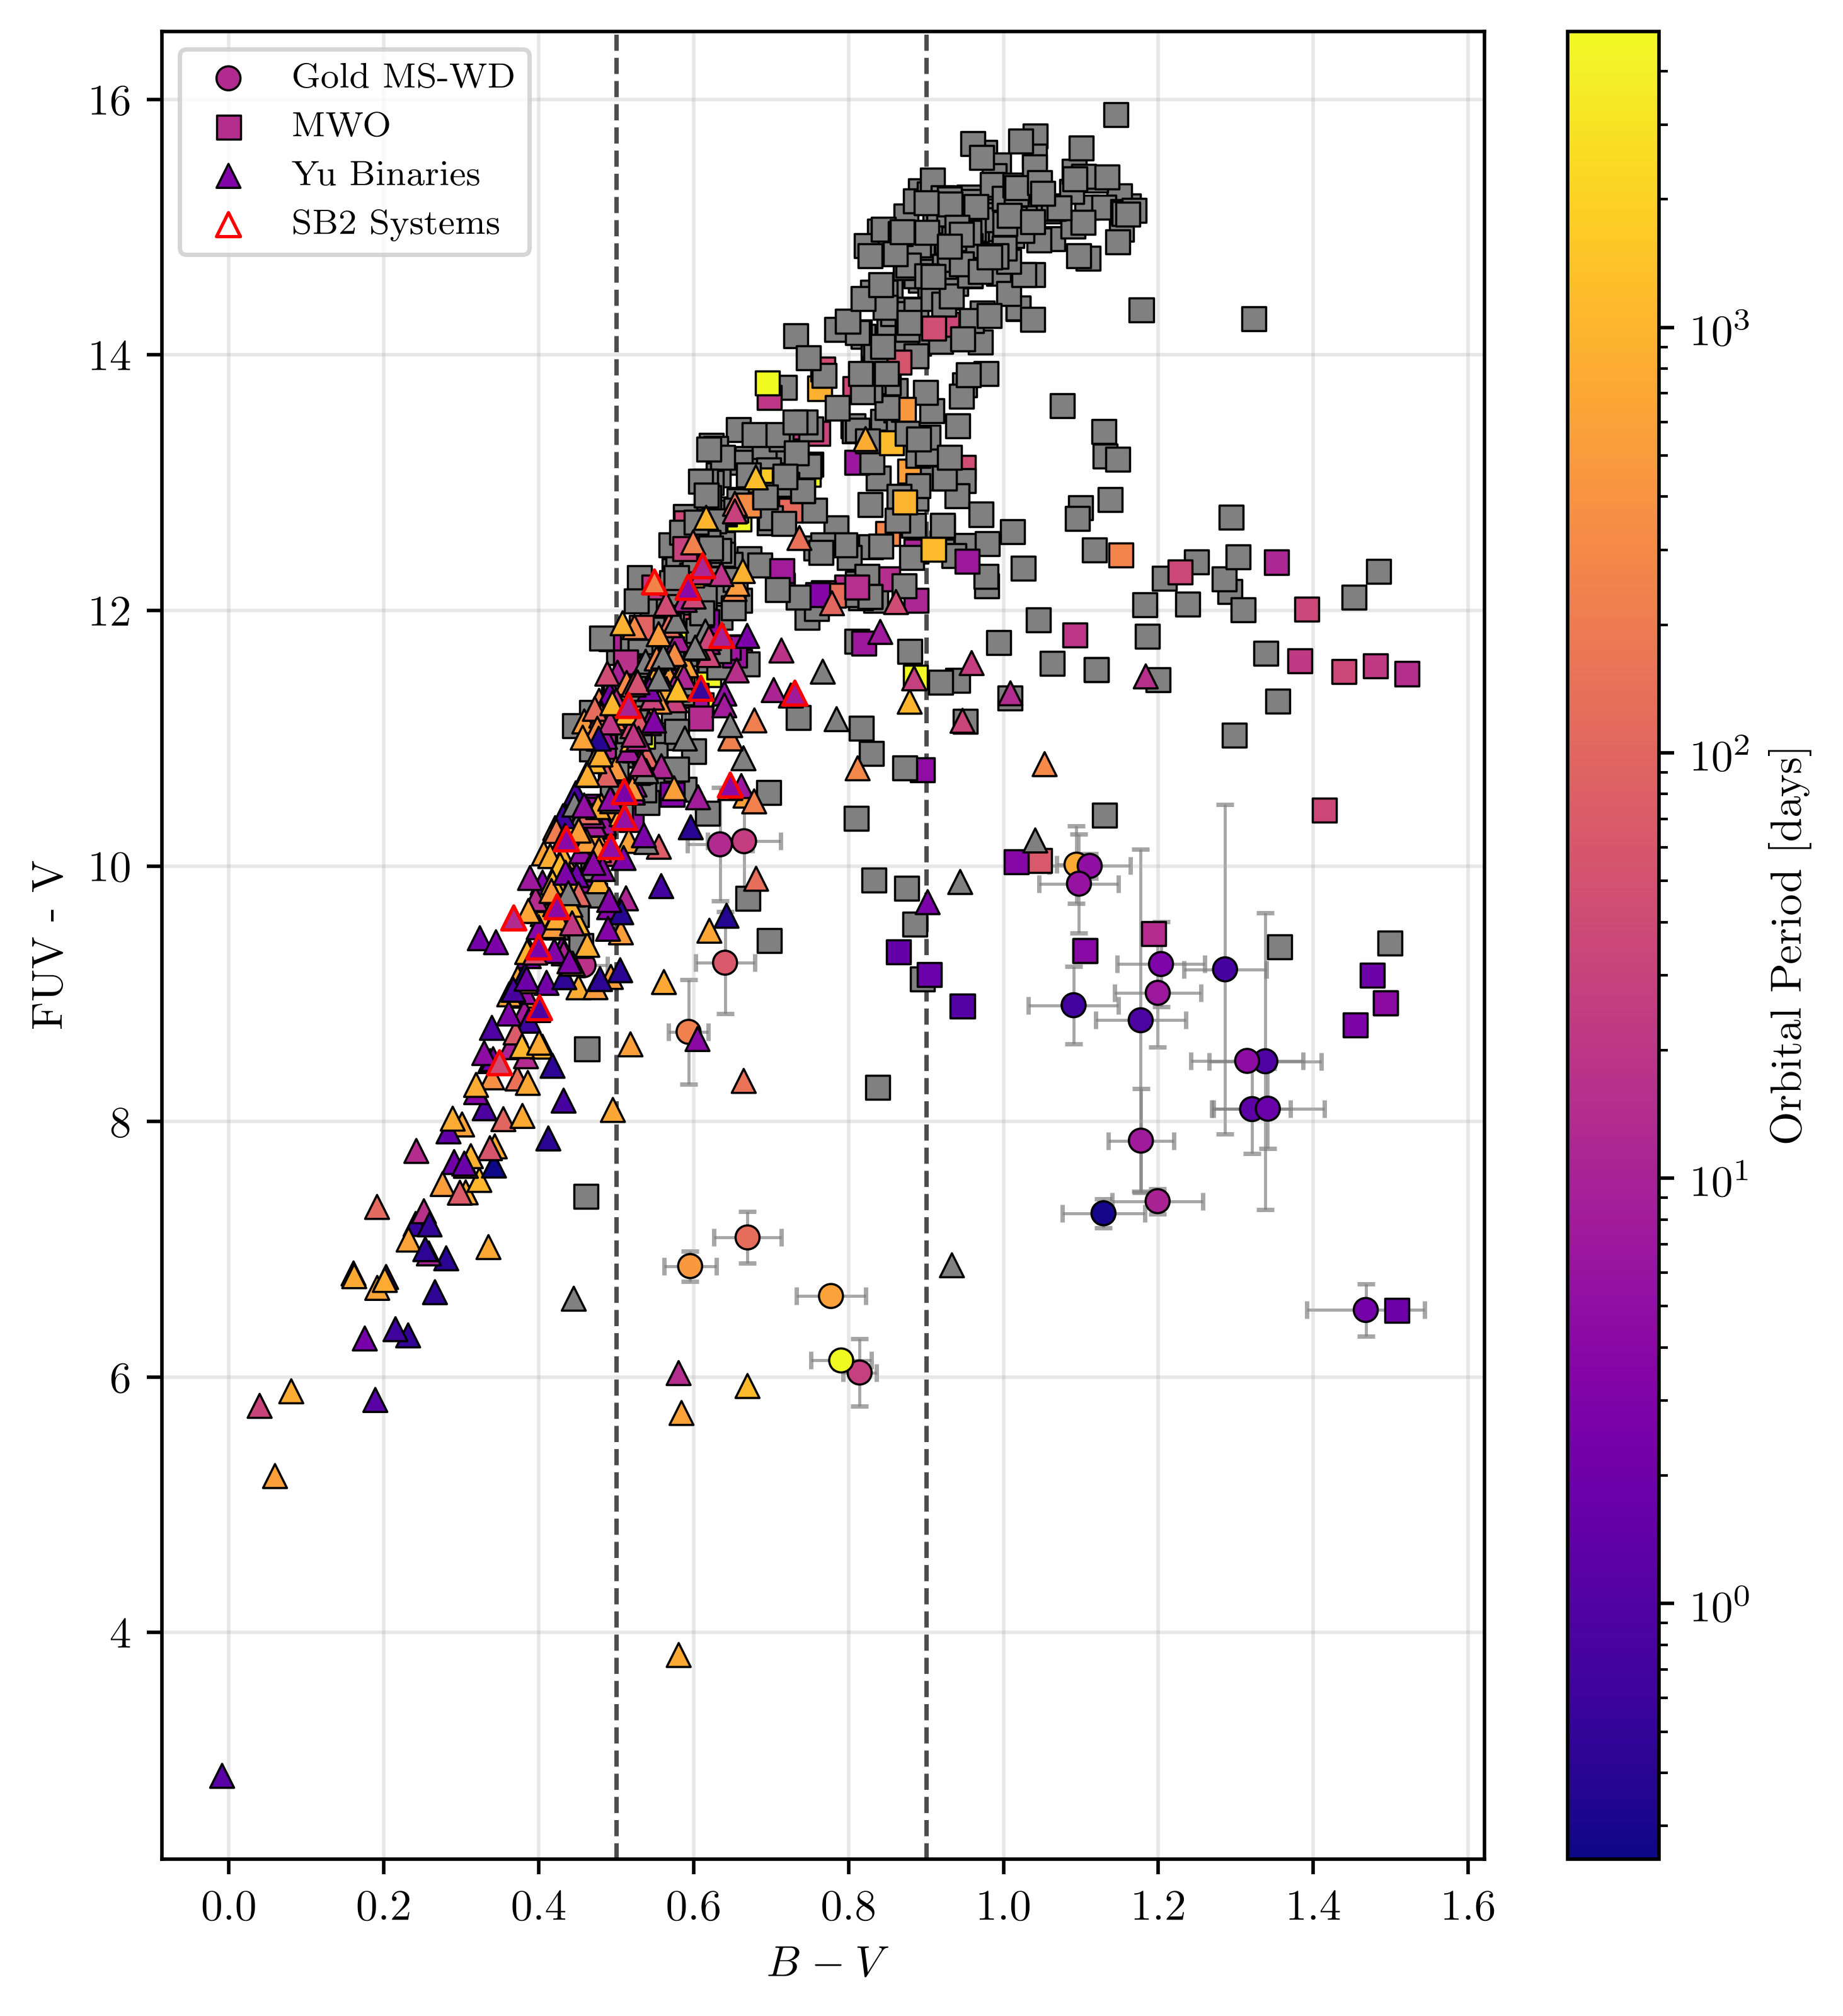

In [470]:
from matplotlib.colors import LinearSegmentedColormap, Normalize

# Load data
path = '/Users/brooklyngustaf/Desktop/Research/Brooklyn_NEID_spectra_project/WDMS2 - WD-MS.csv'
MSWD_df = pd.read_csv(path)
MSWD_df.columns = MSWD_df.columns.str.strip()
MSWD_df["B-V resolved"] = pd.to_numeric(MSWD_df["B-V resolved"], errors="coerce")

# Extract columns
fuv = MSWD_df["FUV obs"]
fuv_err = MSWD_df["FUV obs err"]
fuv2 = MSWD_df["FUV mag (2)"]
fuv_abs_gold = fuv - 5 * np.log10(MSWD_df["Dist [pc]"] / 10)
nuv = MSWD_df["NUV obs"]
v = MSWD_df["v mag"]
v_err = MSWD_df["v err"]
bv = MSWD_df["B-V resolved"]
bv_err = MSWD_df["B-V resolved err"]
logrhk = MSWD_df["logR'_HK (new)"]
teff = MSWD_df["MS Teff"]

# Calculate observed FUV - V and NUV-V
fuv_v = fuv - v
nuv_v = nuv - v
fuv2_v = fuv2 - v

# Propagated FUV - V uncertainty
fuv_v_err = np.sqrt(fuv_err**2 + v_err**2)

fig, ax = plt.subplots(figsize=(6, 6.5), dpi=500)

# B-V range for theoretical curves
AI = np.linspace(0.5, 0.9, 300)

# Fixed V magnitude (set to 0 to plot the conversion offset)
AD = 0

# Representative log R'HK values and curve colors
activity_values = [
    (-3.6, r"$\log R'_{\rm HK} = -3.6$", "magenta", "solid", 0.7),
    (-3.7, None, "magenta", "--", 0.25),
    (-3.8, None, "magenta", "--", 0.25),
    (-3.9, None, "magenta", "--", 0.25),
    (-4.0, None, "magenta", "--", 0.25),
    (-4.1, None, "magenta", "--", 0.25),
    (-4.2, None, "magenta", "--", 0.25),
    # (-4.2, r"$\log R'_{\rm HK} = -4.2$", "magenta"),
    (-4.2, r"$\log R'_{\rm HK} = -4.2$", "red", "solid",0.7),
    # (-4.5, r"$\log R'_{\rm HK} = -4.5$", "red"),
    (-4.5, r"$\log R'_{\rm HK} = -4.5$", "green", "solid", 0.7),
    (-5.0, r"$\log R'_{\rm HK} = -5.0$", "green", "solid", 0.7),
    # (-5.0, r"$\log R'_{\rm HK} = -5.0$", "blue"),
    (-5.2, r"$\log R'_{\rm HK} = -5.2$", "blue", "solid", 0.7),
    # (-5.2, r"$\log R'_{\rm HK} = -5.2$", "purple"),
    (-5.6, r"$\log R'_{\rm HK} = -5.6$", "purple", "solid", 0.7)
]

# Plot Equation (2) curves
for BI, label, color, linestyle, alpha in activity_values:
    x = BI + 4.5
    z = AI - 0.8

    y = (12.30 - 3.95*x - 2.94*x**2
         + 2.22*z - 9.11*z*x - 12.0*z*x**2
         - 17.6*z**2 - 3.9*z**2*x - 24.3*z**2*x**2)

    # ax.plot(AI, y, label=label, color=color, linestyle=linestyle, alpha=alpha)


# # Plot observed stars
# for mask, color, label in groups:
#     valid = mask & bv.notna() & fuv_v.notna() & logrhk.notna()
#     ax.scatter(bv[valid], fuv_v[valid], color=color, s=35, alpha=0.7, label=label)

valid = bv.notna() & fuv_v.notna() & logrhk.notna()
valid_mwo = np.isfinite(bv_mwo) & np.isfinite(fuv_v_mwo) & np.isfinite(logrhk_mittag)
valid_yu = np.isfinite(bv_yu) & np.isfinite(fuv_v_yu) & np.isfinite(logrhk_yu)

bad = valid & ((logrhk > -4.2) | (logrhk < -5.2))
bad_mwo = valid_mwo & ((logrhk_mittag > -4.2) | (logrhk_mittag < -5.2))
bad_yu = valid_yu & ((logrhk_yu > -4.2) | (logrhk_yu < -5.2))
bad_yu_sb2 = bad_yu & sb2_yu
bad_yu_other = bad_yu & ~sb2_yu


good = valid & (logrhk >= -5.2) & (logrhk <= -4.2)
good_mwo = valid_mwo & (logrhk_mittag >= -5.2) & (logrhk_mittag <= -4.2)
good_yu = valid_yu & (logrhk_yu >= -5.2) & (logrhk_yu <= -4.2)
good_yu_sb2 = good_yu & sb2_yu
good_yu_other = good_yu & ~sb2_yu

#! Period Plot
# Gold MS-WD
ax.scatter(bv[good], fuv_v[good], c=colors_msw[good], edgecolors="black", linewidths=0.5,
           s=30, alpha=1, zorder=10, marker="o", label="Gold MS-WD")

ax.scatter(bv[bad], fuv_v[bad], c=colors_msw[bad], edgecolors="black", linewidths=0.5,
           s=30, alpha=1, zorder=11, marker="o")

# MWO
ax.scatter(bv_mwo[good_mwo], fuv_v_mwo[good_mwo], c=colors_mwo[good_mwo],
           edgecolors="black", linewidths=0.5, s=30, alpha=1, zorder=11,
           marker="s", label="MWO")

ax.scatter(bv_mwo[bad_mwo], fuv_v_mwo[bad_mwo], c=colors_mwo[bad_mwo],
           edgecolors="black", linewidths=0.5, s=30, alpha=1, zorder=11,
           marker="s")

# # Add larger, unfilled squares around MWO binary systems
# ax.scatter(bv_mwo[binary_mwo], fuv_v_mwo[binary_mwo],
#            facecolors="none", edgecolors="limegreen",
#            linewidths=0.75, s=30, marker="s",
#            zorder=11, label="MWO Binary Systems")

# Yu binaries: non-SB2
ax.scatter(bv_yu[good_yu_other], fuv_v_yu[good_yu_other], c=colors_yu[good_yu_other],
           edgecolors="black", linewidths=0.5, s=30, alpha=1, zorder=11,
           marker="^", label="Yu Binaries")

ax.scatter(bv_yu[bad_yu_other], fuv_v_yu[bad_yu_other], c=colors_yu[bad_yu_other],
           edgecolors="black", linewidths=0.5, s=30, alpha=1, zorder=11,
           marker="^")

# Yu binaries: SB2
ax.scatter(bv_yu[good_yu_sb2], fuv_v_yu[good_yu_sb2], c=colors_yu[good_yu_sb2],
           edgecolors="black", linewidths=0.5, s=30, alpha=1, zorder=12,
           marker="^", label="")

ax.scatter(bv_yu[bad_yu_sb2], fuv_v_yu[bad_yu_sb2], c=colors_yu[bad_yu_sb2],
           edgecolors="black", linewidths=0.5, s=30, alpha=1, zorder=12,
           marker="^")

# Add larger, unfilled triangles around SB2 systems
ax.scatter(bv_yu[sb2_yu], fuv_v_yu[sb2_yu],
           facecolors="none", edgecolors="red",
           linewidths=0.75, s=30, marker="^",
           zorder=13, label="SB2 Systems")

# Error bars for Gold MS-WD systems
ax.errorbar(bv, fuv_v, xerr=bv_err, yerr=fuv_v_err, fmt="none", ecolor="gray", elinewidth=0.7, capsize=2, alpha=0.7, zorder=1)

#! Period Color Bar
sm = plt.cm.ScalarMappable(cmap=period_cmap, norm=period_norm)
sm.set_array([])

cbar = fig.colorbar(sm, ax=ax)
cbar.set_label("Orbital Period [days]")

# Shade between activity-region boundaries
shade_regions = [
    (-3.6, -4.2, "magenta", 0.2),
    (-4.2, -4.5, "red", 0.2),
    (-4.5, -5.0, "green", 0.2),
    (-5.0, -5.2, "blue", 0.2),
    (-5.2, -5.6, "purple", 0.2)
]

for r1, r2, color, alpha in shade_regions:
    x1, x2 = r1 + 4.5, r2 + 4.5
    z = AI - 0.8

    y1 = (12.30 - 3.95*x1 - 2.94*x1**2
          + 2.22*z - 9.11*z*x1 - 12.0*z*x1**2
          - 17.6*z**2 - 3.9*z**2*x1 - 24.3*z**2*x1**2)

    y2 = (12.30 - 3.95*x2 - 2.94*x2**2
          + 2.22*z - 9.11*z*x2 - 12.0*z*x2**2
          - 17.6*z**2 - 3.9*z**2*x2 - 24.3*z**2*x2**2)

    # ax.fill_between(AI, y1, y2, color=color, alpha=alpha, zorder=0)

plt.axvline(x=0.5, color='black', linestyle='--', linewidth=1, alpha=0.7)
plt.axvline(x=0.9, color='black', linestyle='--', linewidth=1, alpha=0.7)

ax.set_xlabel(r"$B-V$")
ax.set_ylabel("FUV - V")
# ax.set_xlim(0.4, 1.5)
# ax.set_ylim(0, 15)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Total rows in CSV: 32
Rows with valid B-V, NUV-V, and logR'HK: 26
Circle points: 6
Triangle points: 20
    B-V resolved    NUV obs   v mag  logR'_HK (new)
19      0.640576  18.010780  12.569       -4.556298
17      0.665150  18.146381  12.275       -4.538253
15      0.634009  17.806981  12.193       -4.499825
20      0.669640  18.530794  12.929       -4.358262
24      1.094307  20.697364  12.284       -4.340153
21      0.593476  18.898956  14.003       -4.223340

Rows excluded due to missing required values:
    B-V resolved  NUV obs   v mag  logR'_HK (new)
26           NaN      NaN     NaN             NaN
27           NaN      NaN     NaN             NaN
28           NaN      NaN     NaN             NaN
29           NaN      NaN     NaN             NaN
30           NaN      NaN  12.360         -4.0505
31           NaN      NaN  11.807         -3.7892


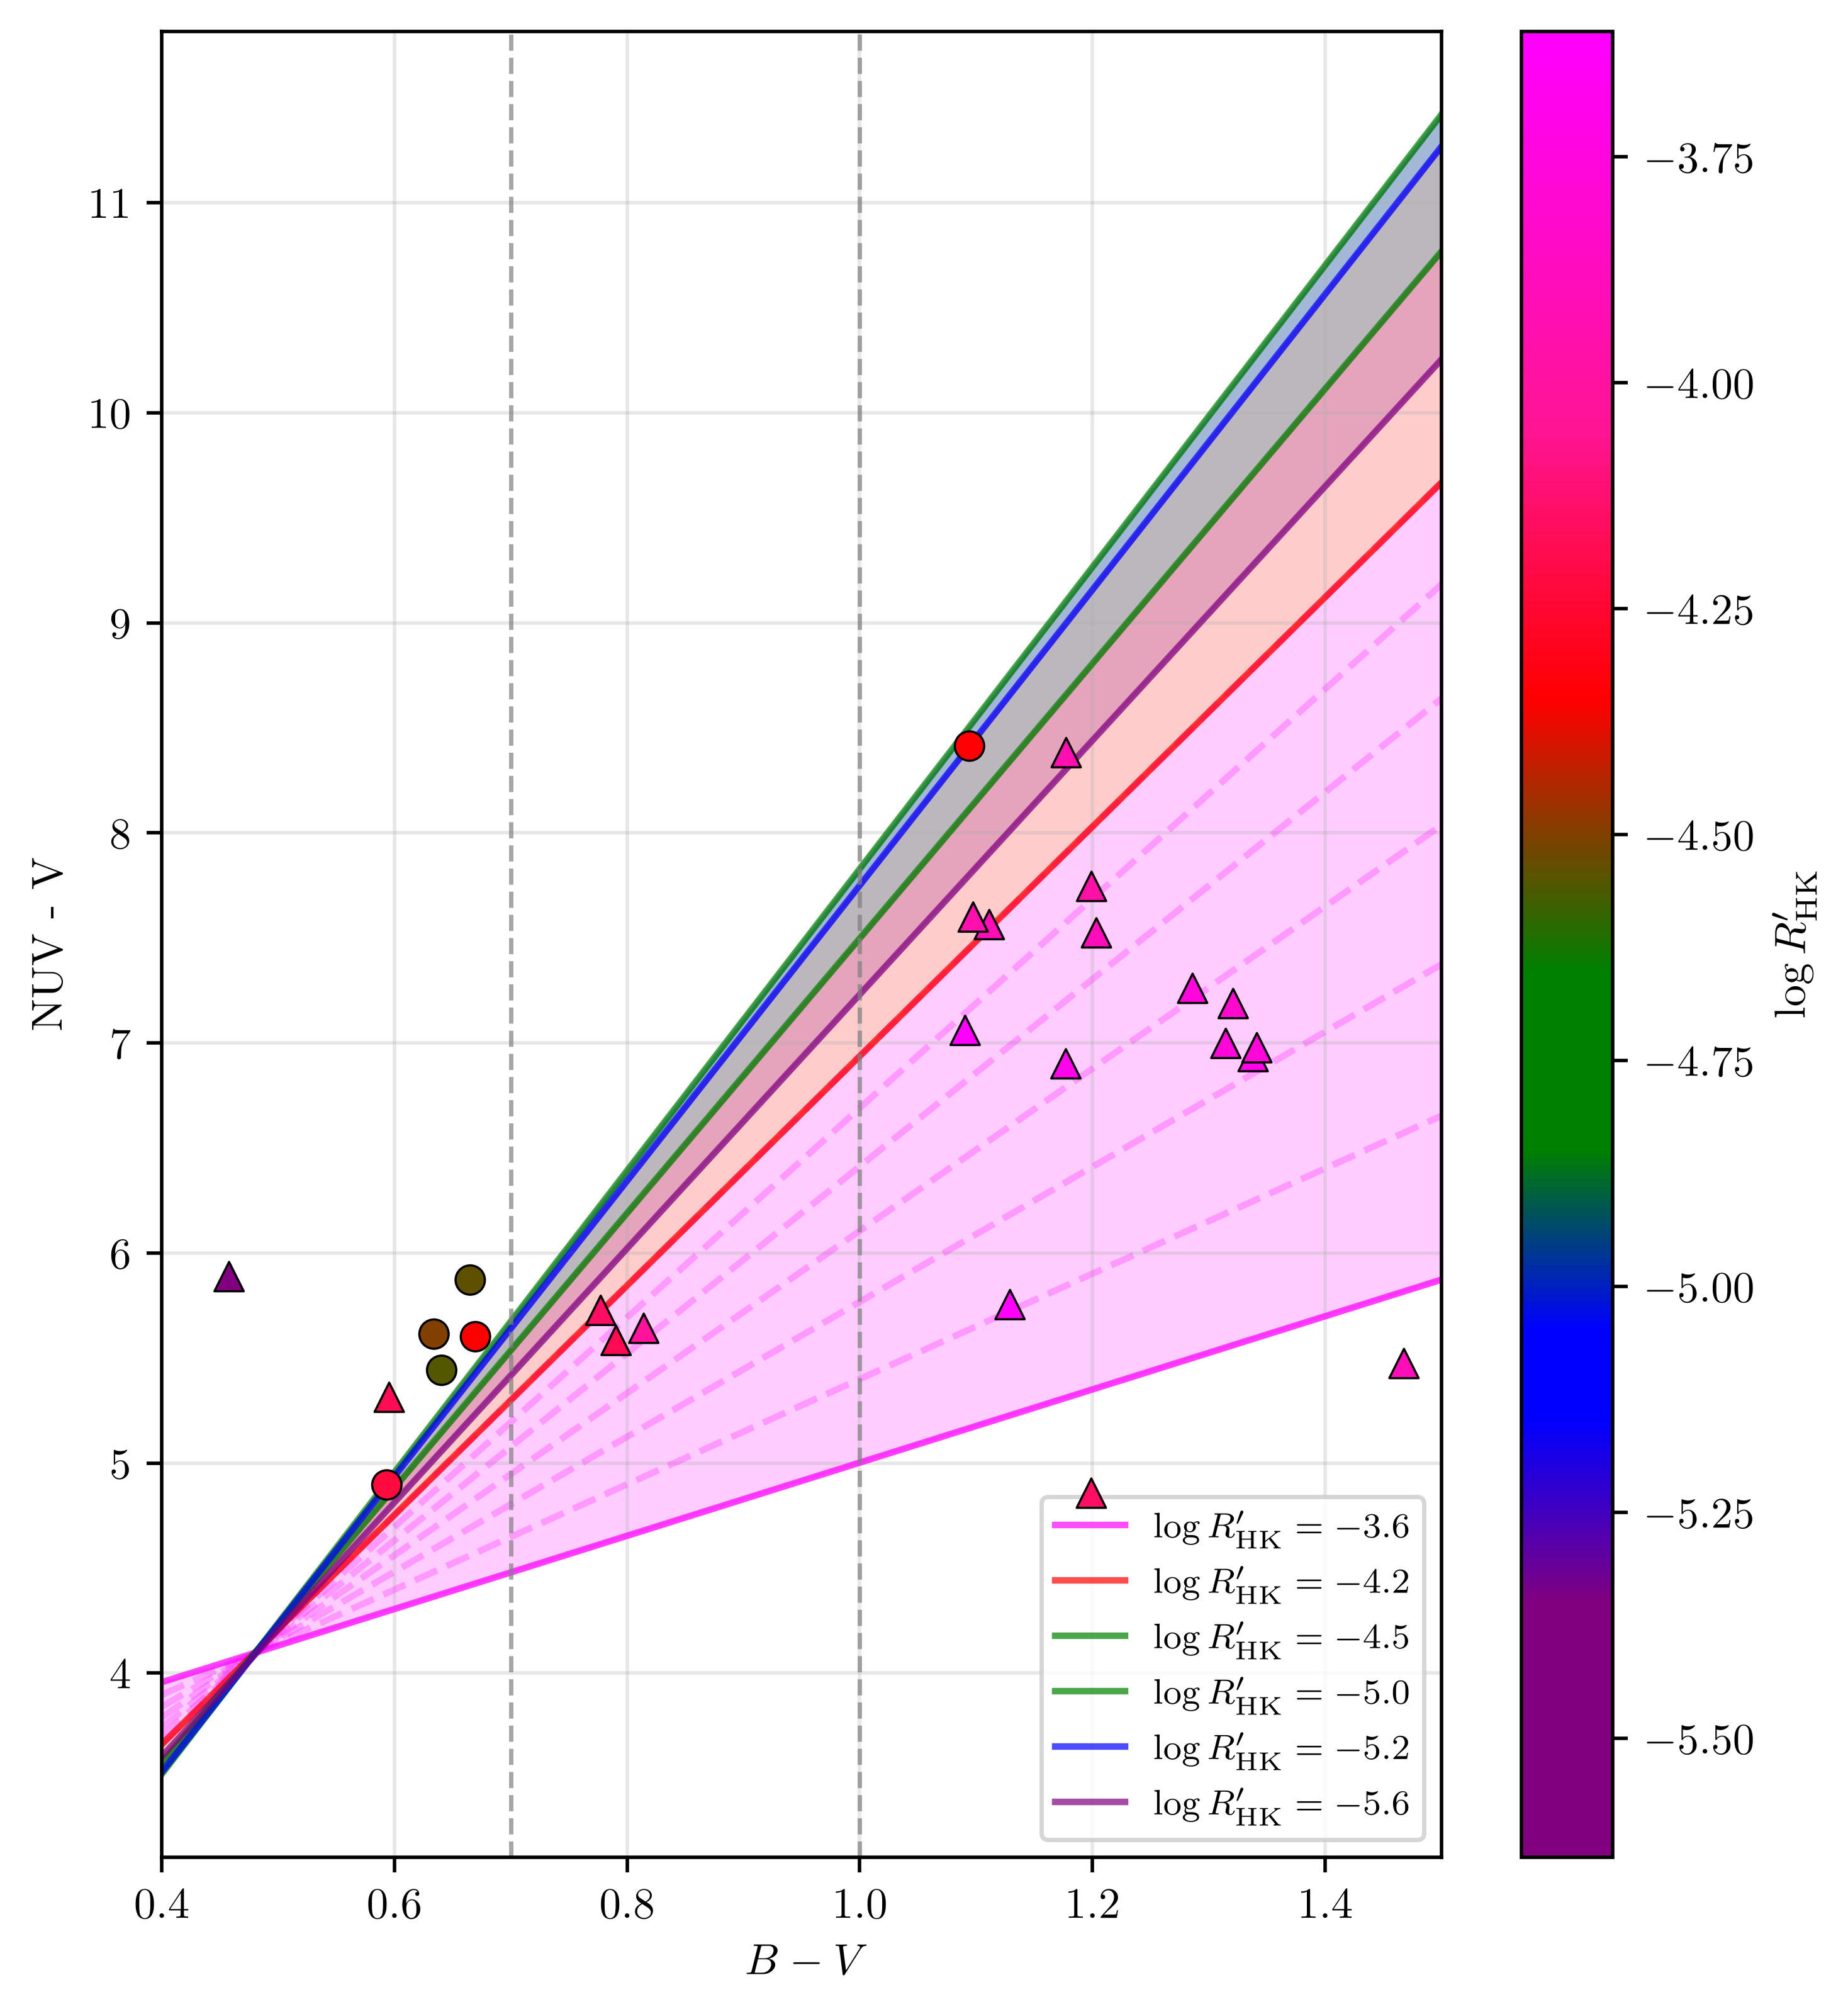

In [37]:
from matplotlib.colors import LinearSegmentedColormap, Normalize

fig, ax = plt.subplots(figsize=(6, 6.5), dpi=500)

# B-V range for theoretical curves
AI = np.linspace(0.4, 1.5, 300)

# Fixed V magnitude (set to 0 to plot the conversion offset)
AD = 0

# Representative log R'HK values and curve colors
activity_values = [
    (-3.6, r"$\log R'_{\rm HK} = -3.6$", "magenta", "solid", 0.7),
    (-3.7, None, "magenta", "--", 0.25),
    (-3.8, None, "magenta", "--", 0.25),
    (-3.9, None, "magenta", "--", 0.25),
    (-4.0, None, "magenta", "--", 0.25),
    (-4.1, None, "magenta", "--", 0.25),
    (-4.2, None, "magenta", "--", 0.25),
    # (-4.2, r"$\log R'_{\rm HK} = -4.2$", "magenta"),
    (-4.2, r"$\log R'_{\rm HK} = -4.2$", "red", "solid",0.7),
    # (-4.5, r"$\log R'_{\rm HK} = -4.5$", "red"),
    (-4.5, r"$\log R'_{\rm HK} = -4.5$", "green", "solid", 0.7),
    (-5.0, r"$\log R'_{\rm HK} = -5.0$", "green", "solid", 0.7),
    # (-5.0, r"$\log R'_{\rm HK} = -5.0$", "blue"),
    (-5.2, r"$\log R'_{\rm HK} = -5.2$", "blue", "solid", 0.7),
    # (-5.2, r"$\log R'_{\rm HK} = -5.2$", "purple"),
    (-5.6, r"$\log R'_{\rm HK} = -5.6$", "purple", "solid", 0.7)
]

# Plot Equation (2) curves
for BI, label, color, linestyle, alpha in activity_values:
    x = BI + 4.5
    z = AI - 0.8

    # y = (12.30 - 3.95*x - 2.94*x**2
    #      + 2.22*z - 9.11*z*x - 12.0*z*x**2
    #      - 17.6*z**2 - 3.9*z**2*x - 24.3*z**2*x**2)

    # y = (AD + 11.19 - 2.17*(BI + 4.5)
    #      - 1.46*(BI + 4.5)**2 + 10.31*(AI - 0.8)
    #      - 7.26*(AI - 0.8)*(BI + 4.5)
    #      - 8.83*(AI - 0.8)*(BI + 4.5)**2)

    y = (6.19 - 0.87*x - 0.93*x**2
     + 6.54*z - 2.73*z*x - 2.89*z*x**2)

    ax.plot(AI, y, label=label, color=color, linestyle=linestyle, alpha=alpha)

# Define observed data activity groups
groups = [
    (logrhk > -4.2, "magenta", r"$\log R'_{\rm HK} > -4.2$"),
    ((logrhk >= -4.5) & (logrhk <= -4.2), "red", r"$-4.5 \leq \log R'_{\rm HK} \leq -4.2$"),
    ((logrhk >= -5.0) & (logrhk <= -4.5), "green",
     r"$-5.0 \leq \log R'_{\rm HK} \leq -4.5$"),
    (logrhk < -5.0, "blue", r"$\log R'_{\rm HK} < -5.0$")
]

# # Plot observed stars
# for mask, color, label in groups:
#     valid = mask & bv.notna() & fuv_v.notna() & logrhk.notna()
#     ax.scatter(bv[valid], fuv_v[valid], color=color, s=35, alpha=0.7, label=label)

valid = bv.notna() & nuv_v.notna() & logrhk.notna()
vmin = logrhk[valid].min()
vmax = logrhk[valid].max()

# Activity boundaries with sharper color transitions
eps = 0.15

activity_points = [
    vmin,
    -5.2 - eps, -5.2 + eps,
    -5.0 - eps, -5.0 + eps,
    -4.5 - eps, -4.5 + eps,
    -4.2 - eps, -4.2 + eps,
    -3.6, vmax
]

activity_colors = [
    "purple",
    "purple", "blue",
    "blue", "green",
    "green", "red",
    "red", "deeppink",
    "deeppink", "magenta"
]

# Keep points within the data range and sort them
color_stops = sorted(
    [(p, c) for p, c in zip(activity_points, activity_colors) if vmin <= p <= vmax],
    key=lambda item: item[0]
)

# Remove duplicate positions to ensure monotonicity
unique_stops = {}
for p, c in color_stops:
    unique_stops[p] = c

points = list(unique_stops.keys())
colors_at_points = list(unique_stops.values())
positions = [(p - vmin) / (vmax - vmin) for p in points]

cmap = LinearSegmentedColormap.from_list("activity", list(zip(positions, colors_at_points)))
norm = Normalize(vmin=vmin, vmax=vmax)

# Triangles: log R'HK > -4.2 or log R'HK < -5.2
triangle = valid & ((logrhk > -4.2) | (logrhk < -5.2))

# Circles: -5.2 <= log R'HK <= -4.2
circle = valid & (logrhk >= -5.2) & (logrhk <= -4.2)

print(f"Total rows in CSV: {len(MSWD_df)}")
print(f"Rows with valid B-V, NUV-V, and logR'HK: {valid.sum()}")
print(f"Circle points: {circle.sum()}")
print(f"Triangle points: {triangle.sum()}")

# Inspect the circle points
print(MSWD_df.loc[circle, ["B-V resolved", "NUV obs", "v mag", "logR'_HK (new)"]].sort_values("logR'_HK (new)"))

# Check rows excluded from the plot
print("\nRows excluded due to missing required values:")
print(MSWD_df.loc[~valid, ["B-V resolved", "NUV obs", "v mag", "logR'_HK (new)"]])

sc = ax.scatter(bv[circle], nuv_v[circle], c=logrhk[circle], edgecolors='black', linewidths=0.5,
                cmap=cmap, norm=norm, s=45, alpha=1, zorder=10, marker='o')

ax.scatter(bv[triangle], nuv_v[triangle], c=logrhk[triangle], edgecolors='black', linewidths=0.5,
           cmap=cmap, norm=norm, s=45, alpha=1, zorder=11, marker='^')

# Add colorbar
cbar = fig.colorbar(sc, ax=ax)
cbar.set_label(r"$\log R'_{\rm HK}$")
# cbar.set_ticks([-5.0, -4.75, -4.5, -4.35, -4.2])

# Shade between activity-region boundaries
shade_regions = [
    (-3.6, -4.2, "magenta", 0.2),
    (-4.2, -4.5, "red", 0.2),
    (-4.5, -5.0, "green", 0.2),
    (-5.0, -5.2, "blue", 0.2),
    (-5.2, -5.6, "purple", 0.2)
]

for r1, r2, color, alpha in shade_regions:
    x1, x2 = r1 + 4.5, r2 + 4.5
    z = AI - 0.8

    y1 = (6.19 - 0.87*x1 - 0.93*x1**2
     + 6.54*z - 2.73*z*x1 - 2.89*z*x1**2)

    y2 = (6.19 - 0.87*x2 - 0.93*x2**2
     + 6.54*z - 2.73*z*x2 - 2.89*z*x2**2)

    ax.fill_between(AI, y1, y2, color=color, alpha=alpha, zorder=0)

plt.axvline(x=0.7, color='gray', linestyle='--', linewidth=1, alpha=0.7)
plt.axvline(x=1.0, color='gray', linestyle='--', linewidth=1, alpha=0.7)

ax.set_xlabel(r"$B-V$")
ax.set_ylabel("NUV - V")
ax.set_xlim(0.4, 1.5)
# ax.set_ylim(0, 15)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# MWO BY Dra Dataset

In [136]:
mwo_data = pd.read_csv('/Users/brooklyngustaf/Desktop/Research/mwo_simbad.txt', sep='\t')
s_index_mwo = np.array(mwo_data["median_s_index"].to_numpy())
distance_pc_mwo = np.array(mwo_data["distance_pc"].to_numpy())
b_mwo = np.array(mwo_data["B"].to_numpy())
v_mwo = np.array(mwo_data["V"].to_numpy())
v_abs_mwo = v_mwo - 5 * np.log10(distance_pc_mwo) + 5
bv_mwo = b_mwo - v_mwo
fuv_mwo = np.array(mwo_data["FUVmag"].to_numpy())
fuv_abs_mwo = fuv_mwo - 5 * np.log10(distance_pc_mwo) + 5
print(fuv_abs_mwo)
fuv_v_mwo = fuv_mwo - v_mwo
nuv_ap_mwo = np.array(mwo_data["NUVmag"].to_numpy())
nuv_abs_mwo = nuv_ap_mwo - 5 * np.log10(distance_pc_mwo) + 5
teff_mwo = np.array(mwo_data["Teff"].to_numpy())

[16.04737783 13.90615368 15.90777544 14.33639125 18.4626589  17.88157966
 18.40976063 15.86185476 18.85202866 18.93805096 18.67953513 18.67571679
 15.33475531 17.83758667 17.88110653 17.82012169 15.92259078         nan
 17.87112188 16.66497172 18.25085949 17.5591283  16.08785198 17.14598995
 16.2010185  16.44156908 16.26617191 19.01177801 15.56082932 18.44006242
 15.6083817  16.04191548]


In [130]:
log_rhk_prime_list = []
for i in range(len(s_index_mwo)):   
    # Initialize the conversion tool
    smw_converter = pyasl.SMW_RHK()

    # Provide the median S-index and the star's B-V color
    s_median = s_index_mwo[i]  # Example solar-like S-index
    b_v_color = bv_mwo[i]  # Example solar B-V color
    t_eff = teff_mwo[i]  # Example solar effective temperature

    # Calculate R_HK prime
    r_hk_prime, r_hk, c_cf, _, _, r_phot = smw_converter.SMWtoRHK(
        S=s_median, bv=b_v_color, lc="ms", Teff=t_eff
    )

    log_rhk_prime = np.log10(r_hk_prime)
    log_rhk_prime_list.append(log_rhk_prime)

log_rhk_prime = np.array(log_rhk_prime_list)
print(log_rhk_prime)


--------------------
| PyA User warning |
--------------------
What happened?
    Noyes et al. 1984 give a validity range of 0.44 < B-V < 0.82 for the photospheric correction. However, the authors use it for B-V > 0.82, where it quickly decreases.

--------------------
| PyA User warning |
--------------------
What happened?
    Noyes et al. 1984 give a validity range of 0.44 < B-V < 0.82 for the photospheric correction. However, the authors use it for B-V > 0.82, where it quickly decreases.

--------------------
| PyA User warning |
--------------------
What happened?
    Noyes et al. 1984 give a validity range of 0.44 < B-V < 0.82 for the photospheric correction. However, the authors use it for B-V > 0.82, where it quickly decreases.

--------------------
| PyA User warning |
--------------------
What happened?
    Noyes et al. 1984 give a validity range of 0.44 < B-V < 0.82 for the photospheric correction. However, the authors use it for B-V > 0.82, where it quickly decreases.

----

# Compare NEID Activity

In [65]:
path = '/Users/brooklyngustaf/Desktop/Research/'

activity_rows = []
indices = ["CaIIHK", "CaIRT1", "CaIRT2", "CaIRT3"]

for tic in tic_id:
    folder_path = path + f'Brooklyn_NEID_spectra_project/l2fits/TIC_{tic}'

    for filename in os.listdir(folder_path):
        if not filename.endswith(".fits"):
            continue

        file_path = os.path.join(folder_path, filename)

        with fits.open(file_path) as hdul:
            activity = Table(hdul[13].data).to_pandas()

            row = {"TIC": tic, "observation": filename}

            for index_name in indices:
                matches = activity[activity["INDEX"].astype(str).str.strip() == index_name]

                if not matches.empty:
                    row[index_name] = matches["VALUE"].iloc[0]
                    row[f"{index_name}_uncertainty"] = matches["UNCERTAINTY"].iloc[0]
                else:
                    row[index_name] = np.nan
                    row[f"{index_name}_uncertainty"] = np.nan

            activity_rows.append(row)

activity_df = pd.DataFrame(activity_rows)

# print(activity_df.head())

print(activity_df)

          TIC                  observation     CaIIHK  CaIIHK_uncertainty  \
0    63939535  neidL2_20241214T023531.fits  -0.609661           -0.488928   
1    63939535  neidL2_20241013T070109.fits  -6.090459           -2.654698   
2    63939535  neidL2_20241121T034129.fits  -4.209032            1.606208   
3    63939535  neidL2_20241204T025424.fits -15.448006           -8.510117   
4    63939535  neidL2_20241206T025626.fits  -4.733385           -1.470282   
..        ...                          ...        ...                 ...   
291  67907704  neidL2_20251031T122438.fits   0.368645            0.058623   
292  67907704  neidL2_20241014T122902.fits   0.378466            0.072507   
293  67907704  neidL2_20251018T123509.fits   0.274356            0.105836   
294  67907704  neidL2_20260224T065124.fits   0.277806            0.082322   
295  67907704  neidL2_20250202T035336.fits  -0.041830            0.070398   

       CaIRT1  CaIRT1_uncertainty    CaIRT2  CaIRT2_uncertainty    CaIRT3  

In [66]:
summary_df = activity_df.groupby("TIC")[indices].agg(["mean", "std", "count"])
summary_df.columns = [f"{col}_{stat}" for col, stat in summary_df.columns]
summary_df = summary_df.reset_index()
print(summary_df)

          TIC  CaIIHK_mean  CaIIHK_std  CaIIHK_count  CaIRT1_mean  CaIRT1_std  \
0     8200813     0.060114    1.669239            14     0.654477    0.143476   
1     9429166     2.195432    6.120381            11     0.850954    0.031703   
2    16117219    -1.526128    1.615773            13     0.878614    0.199365   
3    39718658    -1.098321    1.500366            10     0.508108    0.157243   
4    63082902     0.705264    0.353228            19     1.232468    0.989798   
5    63939535    -5.718414    5.106733             6     0.979522    0.036061   
6    67907704     0.215662    0.143933             8     0.642064    0.021381   
7    70666120    -1.613839    4.145597            10     0.760784    0.324940   
8   117249718    -0.108388    1.664423            10     0.651401    0.099972   
9   136954576     0.680562    0.235062            13     0.828488    0.154933   
10  168707425    -8.491235   43.440183            10     0.955351    0.054660   
11  202364425    -0.106319  

In [68]:
stellar_params = MSWD_df[["TIC", "B-V resolved", "MS Teff", "logR'_HK (new)"]].copy()
stellar_params["TIC"] = pd.to_numeric(stellar_params["TIC"], errors="coerce").astype("Int64")
stellar_params = stellar_params.dropna(subset=["TIC"])

summary_df["TIC"] = pd.to_numeric(summary_df["TIC"], errors="coerce").astype("Int64")

summary_df = summary_df.merge(stellar_params, on="TIC", how="left", validate="one_to_one")
print(summary_df)

          TIC  CaIIHK_mean  CaIIHK_std  CaIIHK_count  CaIRT1_mean  CaIRT1_std  \
0     8200813     0.060114    1.669239            14     0.654477    0.143476   
1     9429166     2.195432    6.120381            11     0.850954    0.031703   
2    16117219    -1.526128    1.615773            13     0.878614    0.199365   
3    39718658    -1.098321    1.500366            10     0.508108    0.157243   
4    63082902     0.705264    0.353228            19     1.232468    0.989798   
5    63939535    -5.718414    5.106733             6     0.979522    0.036061   
6    67907704     0.215662    0.143933             8     0.642064    0.021381   
7    70666120    -1.613839    4.145597            10     0.760784    0.324940   
8   117249718    -0.108388    1.664423            10     0.651401    0.099972   
9   136954576     0.680562    0.235062            13     0.828488    0.154933   
10  168707425    -8.491235   43.440183            10     0.955351    0.054660   
11  202364425    -0.106319  

In [71]:
neid_logrhk_list = []
my_logrhk_list = []
for i in range(len(summary_df['TIC'])):   
    # Initialize the conversion tool
    smw_converter = pyasl.SMW_RHK()

    # Provide the median S-index and the star's B-V color
    s_median = summary_df['CaIIHK_mean'].iloc[i]  # Example solar-like S-index
    b_v_color = summary_df['B-V resolved'].iloc[i]  # Example solar B-V color
    t_eff = summary_df['MS Teff'].iloc[i]  # Example solar effective temperature
    my_logrhk = summary_df["logR'_HK (new)"].iloc[i]
    my_logrhk_list.append(my_logrhk)

    # Calculate R_HK prime
    r_hk_prime, r_hk, c_cf, _, _, r_phot = smw_converter.SMWtoRHK(
        S=s_median, bv=b_v_color, lc="ms", Teff=t_eff
    )

    log_rhk_prime = np.log10(r_hk_prime)
    neid_logrhk_list.append(log_rhk_prime)

neid_logrhks = np.array(neid_logrhk_list)
my_logrhks = np.array(my_logrhk_list)
compare_rhk = pd.DataFrame({
    "TIC": summary_df["TIC"].to_numpy(),
    "NEID logR'HK": neid_logrhk_list,
    "My logR'HK": my_logrhk_list
})
print(compare_rhk)

--------------------
| PyA User warning |
--------------------
What happened?
    Noyes et al. 1984 give a validity range of 0.44 < B-V < 0.82 for the photospheric correction. However, the authors use it for B-V > 0.82, where it quickly decreases.

--------------------
| PyA User warning |
--------------------
What happened?
    Noyes et al. 1984 give a validity range of 0.44 < B-V < 0.82 for the photospheric correction. However, the authors use it for B-V > 0.82, where it quickly decreases.

--------------------
| PyA User warning |
--------------------
What happened?
    Noyes et al. 1984 give a validity range of 0.44 < B-V < 0.82 for the photospheric correction. However, the authors use it for B-V > 0.82, where it quickly decreases.

--------------------
| PyA User warning |
--------------------
What happened?
    Noyes et al. 1984 give a validity range of 0.44 < B-V < 0.82 for the photospheric correction. However, the authors use it for B-V > 0.82, where it quickly decreases.

----

/var/folders/l4/_mvnx6k155979tth3g7sqpmr0000gn/T/ipykernel_76955/1201864742.py:19: RuntimeWarning: invalid value encountered in log10
  log_rhk_prime = np.log10(r_hk_prime)


--------------------
| PyA User warning |
--------------------
What happened?
    Noyes et al. 1984 give a validity range of 0.44 < B-V < 0.82 for the photospheric correction. However, the authors use it for B-V > 0.82, where it quickly decreases.

--------------------
| PyA User warning |
--------------------
What happened?
    Noyes et al. 1984 give a validity range of 0.44 < B-V < 0.82 for the photospheric correction. However, the authors use it for B-V > 0.82, where it quickly decreases.

--------------------
| PyA User warning |
--------------------
What happened?
    Noyes et al. 1984 give a validity range of 0.44 < B-V < 0.82 for the photospheric correction. However, the authors use it for B-V > 0.82, where it quickly decreases.

--------------------
| PyA User warning |
--------------------
What happened?
    Noyes et al. 1984 give a validity range of 0.44 < B-V < 0.82 for the photospheric correction. However, the authors use it for B-V > 0.82, where it quickly decreases.

----

In [165]:
neid_logrhk_s_list = []
neid_logrhk_n_list = []
my_logrhk_list = []
s_mw_list = []
intermediate = []

for i in range(len(summary_df)):
    s_neid = summary_df["CaIIHK_mean"].iloc[i]
    bv = summary_df["B-V resolved"].iloc[i]
    t_eff = summary_df['MS Teff'].iloc[i]
    my_logrhk = summary_df["logR'_HK (new)"].iloc[i]

    my_logrhk_list.append(my_logrhk)

    if pd.isna(s_neid) or pd.isna(bv) or not (0.4 <= bv <= 1.9):
        s_mw_list.append(np.nan)
        neid_logrhk_s_list.append(np.nan)
        neid_logrhk_n_list.append(np.nan)
        continue

    # Provisional NEID DRP -> Mount Wilson calibration
    s_mw = 1.177 * s_neid + 0.004
    s_mw_list.append(s_mw)

    # Suárez Mascareño et al. (2015) extended calibration
    log_ccf_s = 0.668 * bv**3 - 1.270 * bv**2 - 0.645 * bv - 0.443
    c_cf_s = 10**log_ccf_s
    r_hk_s = 1.34e-4 * c_cf_s * s_mw
    r_phot_s = 1.48e-4 * np.exp(-4.3658 * bv)
    r_hk_prime_s = r_hk_s - r_phot_s

    neid_logrhk_s_list.append(np.log10(r_hk_prime_s) if r_hk_prime_s > 0 else np.nan)

    # Calculate R_HK prime
    r_hk_prime_n, r_hk_n, c_cf_n, _, _, r_phot_n = smw_converter.SMWtoRHK(
        S=s_mw, bv=bv, lc="ms", Teff=t_eff
    )

    neid_logrhk_n_list.append(np.log10(r_hk_prime_n) if r_hk_prime_n > 0 else np.nan)

    intermediate.append({
    "TIC": summary_df["TIC"].iloc[i],
    "B-V": bv,
    "Teff": t_eff,
    "S_MW": s_mw,
    "Ccf extended": c_cf_s,
    "RHK extended": r_hk_s,
    "Rphot extended": r_phot_s,
    "RHK_prime extended": r_hk_prime_s,
    "Ccf Noyes": c_cf_n,
    "RHK Noyes": r_hk_n,
    "Rphot Noyes": r_phot_n,
    "RHK_prime Noyes": r_hk_prime_n
})


compare_rhk = pd.DataFrame({
    "TIC": summary_df["TIC"].to_numpy(),
    "NEID S-index": summary_df["CaIIHK_mean"].to_numpy(),
    "S_MW (provisional)": s_mw_list,
    "NEID logR'HK (extended)": neid_logrhk_s_list,
    "NEID logR'HK (Noyes)": neid_logrhk_n_list,
    "My logR'HK": my_logrhk_list
})

# print(compare_rhk)

intermediate_df = pd.DataFrame(intermediate)
print(intermediate_df.to_string(index=False))

--------------------
| PyA User warning |
--------------------
What happened?
    Noyes et al. 1984 give a validity range of 0.44 < B-V < 0.82 for the photospheric correction. However, the authors use it for B-V > 0.82, where it quickly decreases.

--------------------
| PyA User warning |
--------------------
What happened?
    Noyes et al. 1984 give a validity range of 0.44 < B-V < 0.82 for the photospheric correction. However, the authors use it for B-V > 0.82, where it quickly decreases.

--------------------
| PyA User warning |
--------------------
What happened?
    Noyes et al. 1984 give a validity range of 0.44 < B-V < 0.82 for the photospheric correction. However, the authors use it for B-V > 0.82, where it quickly decreases.

--------------------
| PyA User warning |
--------------------
What happened?
    Noyes et al. 1984 give a validity range of 0.44 < B-V < 0.82 for the photospheric correction. However, the authors use it for B-V > 0.82, where it quickly decreases.

----

In [80]:
test = pd.read_csv("/Users/brooklyngustaf/Desktop/Research/NEID_Activity/Ca_II_IRT_activity_results_test.csv")
compare_I = pd.DataFrame({
    "TIC": test["TIC"].to_numpy(),
    "NEID I1": test["NEID_CaIRT1"].to_numpy(),
    "My I1": test["IRT1_I"].to_numpy(),
    "NEID I2": test["NEID_CaIRT2"].to_numpy(),
    "My I2": test["IRT2_I"].to_numpy(),
    "NEID I3": test["NEID_CaIRT3"].to_numpy(),
    "My I3": test["IRT3_I"].to_numpy()
})
# print(compare_I)
compare_df = pd.merge(compare_rhk, compare_I, on="TIC", how="inner")
print(compare_df)

          TIC  NEID logR'HK  My logR'HK   NEID I1     My I1   NEID I2  \
0     8200813     -5.734703   -4.340153  0.841624  0.668285  0.773289   
1     9429166     -4.092920   -3.942628  0.825749  0.793829  0.769008   
2    16117219           NaN   -3.763432  0.991694  0.911774  0.962582   
3    39718658           NaN   -4.556298  0.438098  0.671312  0.278307   
4    63082902     -4.751843   -4.144250  0.555143  0.715395  0.461883   
5    63939535           NaN   -3.638336  1.031814  0.939491  0.893550   
6    67907704     -4.850691   -4.184187  0.642637  0.713062  0.563751   
7    70666120           NaN   -4.358262  0.470562  0.696407  0.416133   
8   117249718           NaN   -4.179046  0.577455  0.732730  0.575748   
9   136954576     -4.731985   -3.935060  0.966152  0.792318  0.696083   
10  168707425           NaN   -3.704938  0.968889  0.914960  0.919035   
11  202364425           NaN   -3.896961  0.935248  0.894398  0.976382   
12  236017803           NaN   -3.710389  1.028616  

  Index  N  Slope  Intercept     R²  Pearson r   p-value   RMSE
NEID I1 26  1.505     -5.291 0.5346     0.7312 2.207e-05 0.2818
NEID I2 26  1.287      -5.01 0.5273     0.7262 2.674e-05  0.284
NEID I3 26  1.428     -5.068 0.5071     0.7121 4.498e-05   0.29
  My I1 26  3.196     -6.653 0.5751     0.7584 7.157e-06 0.2692
  My I2 26  2.793     -6.167 0.7101     0.8427 6.644e-08 0.2224
  My I3 26  3.505     -6.621 0.6616     0.8134 4.384e-07 0.2403
  Index  N    Slope  Intercept        R²  Pearson r  p-value   RMSE
NEID I1 13  -0.8336     -3.861   0.03843     -0.196    0.521 0.6866
NEID I2 13  -0.5647     -4.132   0.02655    -0.1629   0.5948 0.6908
NEID I3 13 -0.02449      -4.53 4.272e-05  -0.006536   0.9831 0.7002
  My I1 13  -0.7088     -3.994  0.006586   -0.08115   0.7921 0.6979
  My I2 13    -1.22     -3.664   0.03132     -0.177    0.563 0.6891
  My I3 13  -0.1672     -4.429 0.0003828   -0.01956   0.9494    0.7


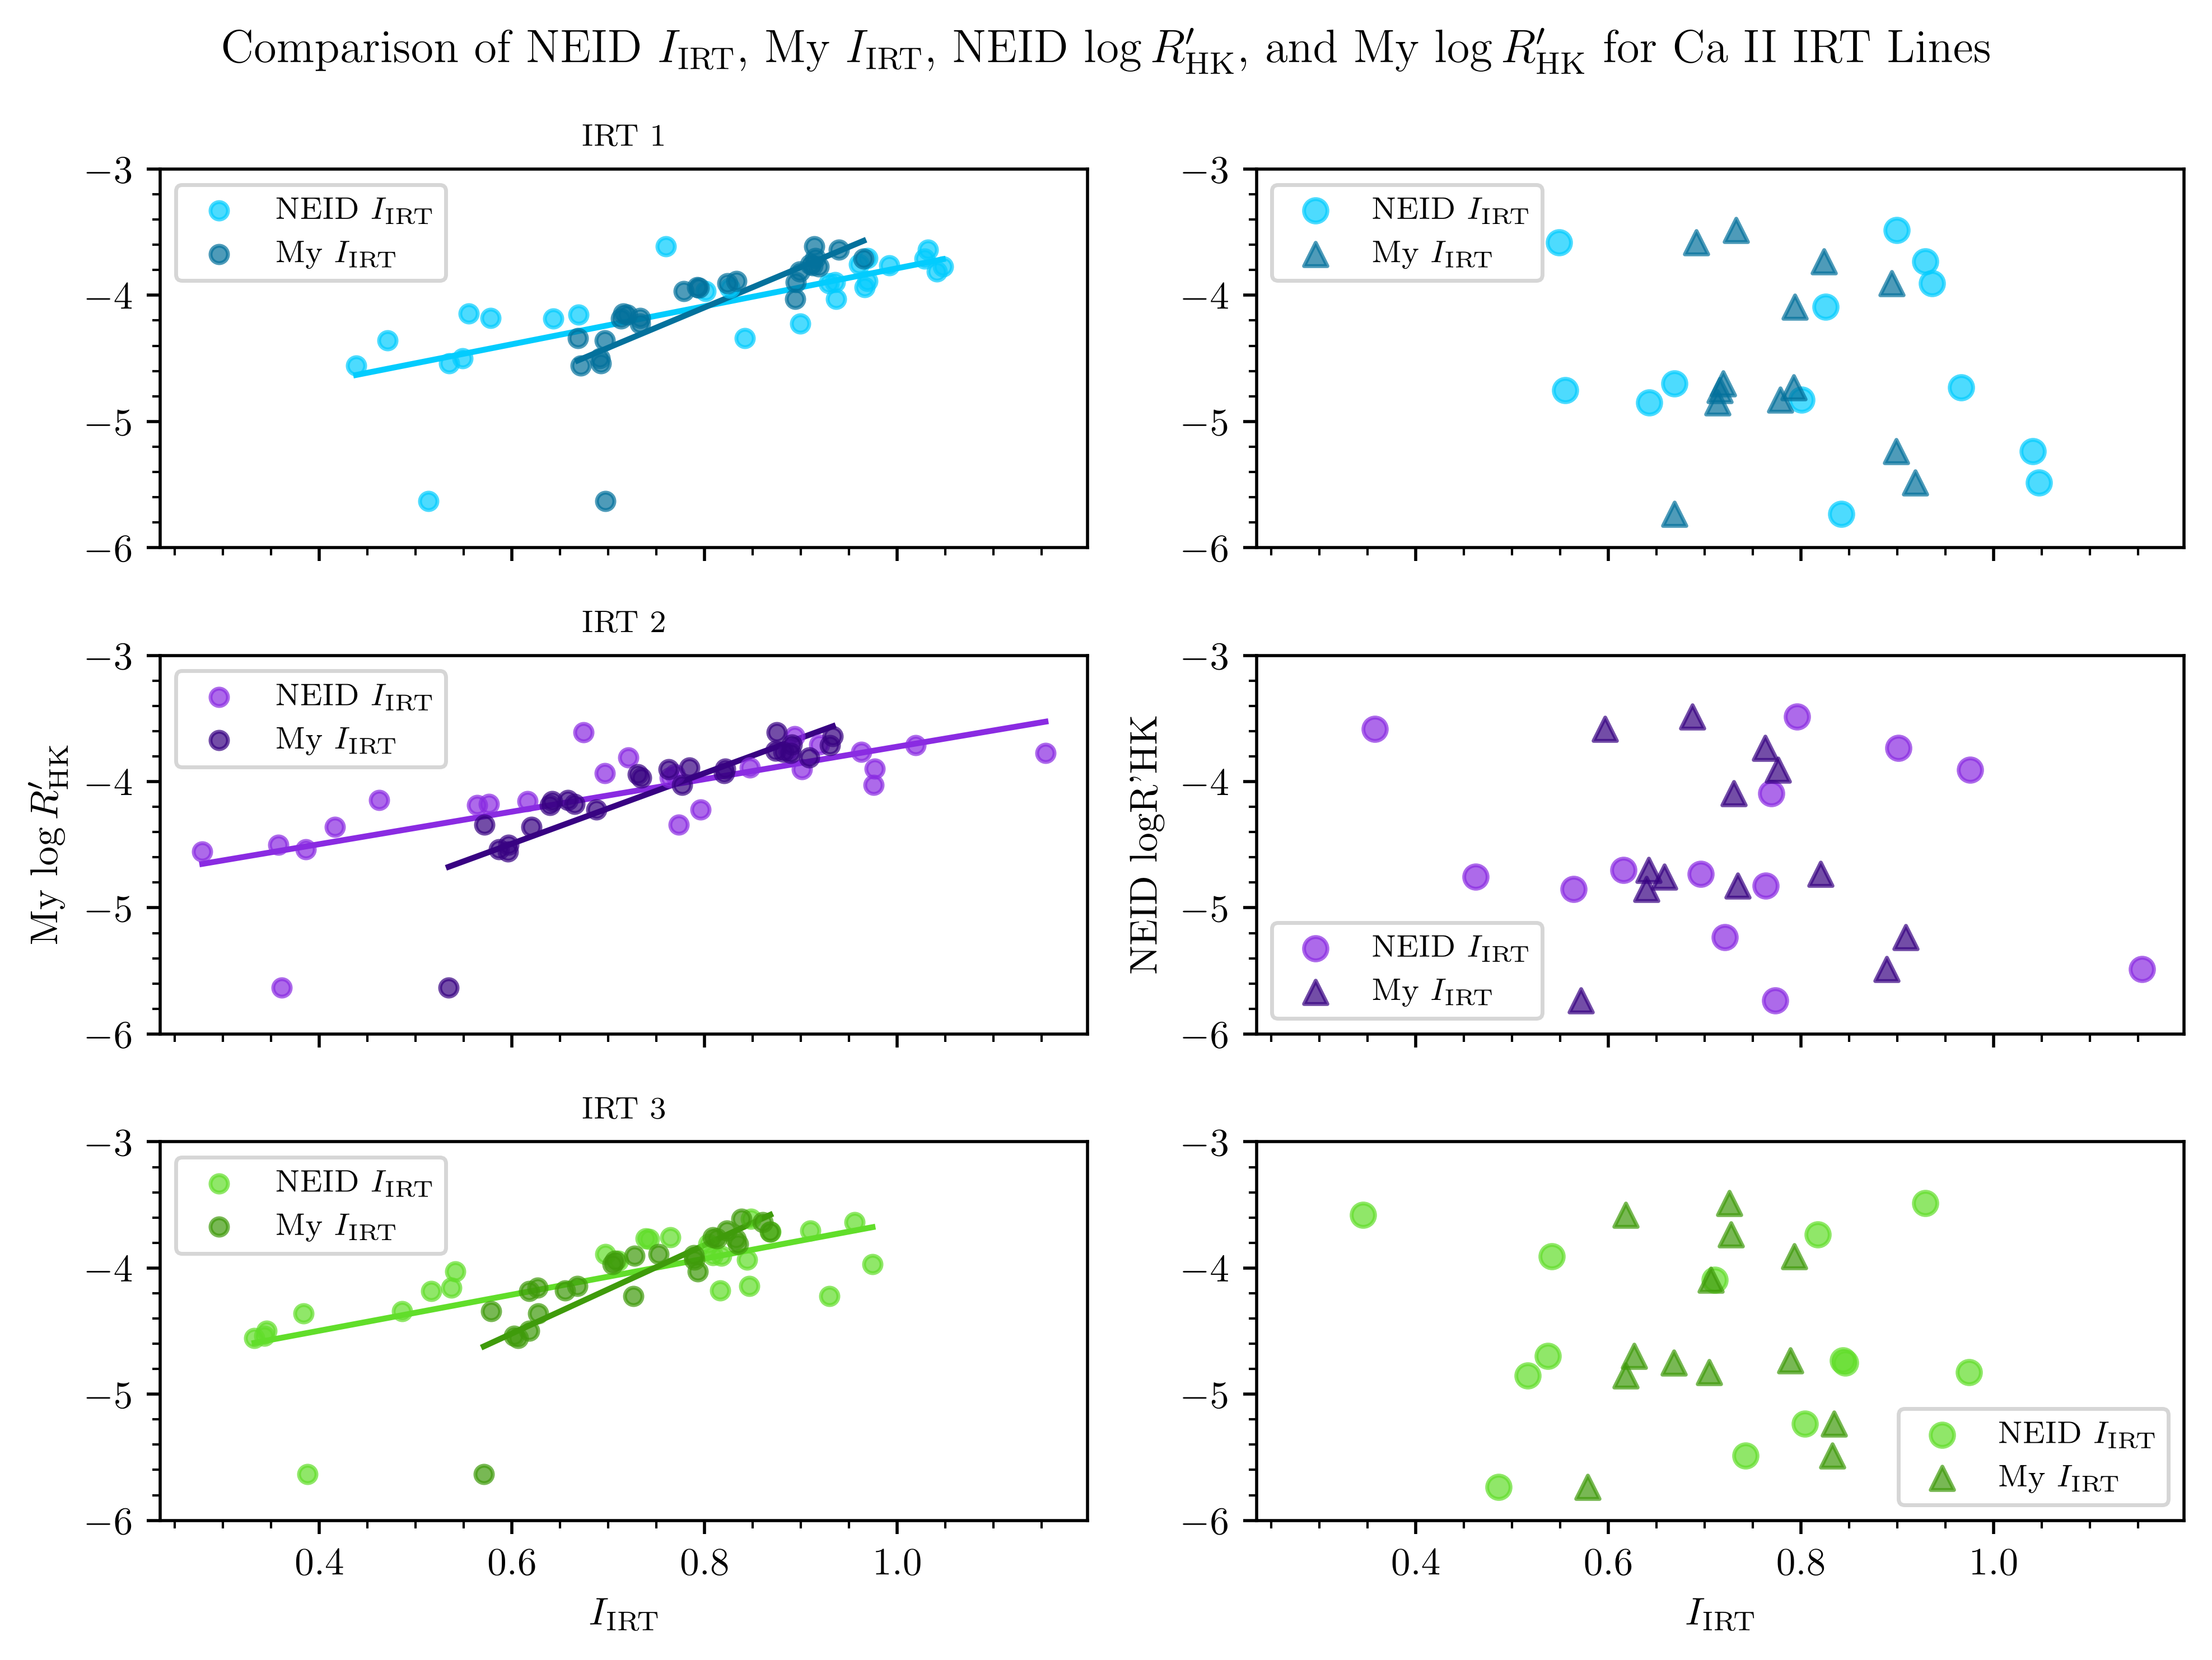

In [240]:
fit1 = np.polyfit(compare_df["NEID I1"], compare_df["My logR'HK"], 1)
fit2 = np.polyfit(compare_df["NEID I2"], compare_df["My logR'HK"], 1)
fit3 = np.polyfit(compare_df["NEID I3"], compare_df["My logR'HK"], 1)
fit4 = np.polyfit(compare_df["My I1"], compare_df["My logR'HK"], 1)
fit5 = np.polyfit(compare_df["My I2"], compare_df["My logR'HK"], 1)
fit6 = np.polyfit(compare_df["My I3"], compare_df["My logR'HK"], 1)

from scipy import stats
import numpy as np
import pandas as pd

y = compare_df["My logR'HK"]

x_columns = {
    "NEID I1": compare_df["NEID I1"],
    "NEID I2": compare_df["NEID I2"],
    "NEID I3": compare_df["NEID I3"],
    "My I1": compare_df["My I1"],
    "My I2": compare_df["My I2"],
    "My I3": compare_df["My I3"]
}

results = []

for name, x in x_columns.items():
    data = pd.DataFrame({"x": x, "y": y}).replace([np.inf, -np.inf], np.nan).dropna()
    x_clean, y_clean = data["x"], data["y"]
    fit = stats.linregress(x_clean, y_clean)
    y_pred = fit.intercept + fit.slope * x_clean

    results.append({
        "Index": name,
        "N": len(data),
        "Slope": fit.slope,
        "Intercept": fit.intercept,
        "R²": fit.rvalue**2,
        "Pearson r": fit.rvalue,
        "p-value": fit.pvalue,
        "RMSE": np.sqrt(np.mean((y_clean - y_pred)**2))
    })

stats_df = pd.DataFrame(results)
print(stats_df.to_string(index=False, float_format=lambda v: f"{v:.4g}"))

fit7 = np.polyfit(compare_df["NEID I1"], compare_df["NEID logR'HK"], 1)
fit8 = np.polyfit(compare_df["NEID I2"], compare_df["NEID logR'HK"], 1)
fit9 = np.polyfit(compare_df["NEID I3"], compare_df["NEID logR'HK"], 1)
fit10 = np.polyfit(compare_df["My I1"], compare_df["NEID logR'HK"], 1)
fit11 = np.polyfit(compare_df["My I2"], compare_df["NEID logR'HK"], 1)
fit12 = np.polyfit(compare_df["My I3"], compare_df["NEID logR'HK"], 1)

y = compare_df["NEID logR'HK"]

x_columns = {
    "NEID I1": compare_df["NEID I1"],
    "NEID I2": compare_df["NEID I2"],
    "NEID I3": compare_df["NEID I3"],
    "My I1": compare_df["My I1"],
    "My I2": compare_df["My I2"],
    "My I3": compare_df["My I3"]
}

results = []

for name, x in x_columns.items():
    data = pd.DataFrame({"x": x, "y": y}).replace([np.inf, -np.inf], np.nan).dropna()
    x_clean, y_clean = data["x"], data["y"]
    fit = stats.linregress(x_clean, y_clean)
    y_pred = fit.intercept + fit.slope * x_clean

    results.append({
        "Index": name,
        "N": len(data),
        "Slope": fit.slope,
        "Intercept": fit.intercept,
        "R²": fit.rvalue**2,
        "Pearson r": fit.rvalue,
        "p-value": fit.pvalue,
        "RMSE": np.sqrt(np.mean((y_clean - y_pred)**2))
    })

stats_df = pd.DataFrame(results)
print(stats_df.to_string(index=False, float_format=lambda v: f"{v:.4g}"))

fig, ax = plt.subplots(3, 2, figsize=(8, 6), dpi=500, sharex=True, sharey=True)

ax[0, 0].scatter(compare_I["NEID I1"], test["log_RHK_total"], label=r"NEID $I_{\rm IRT}$", color='xkcd:bright sky blue', alpha=0.7, s=20, zorder=10)
ax[1, 0].scatter(compare_I["NEID I2"], test["log_RHK_total"], label=r"NEID $I_{\rm IRT}$", color='blueviolet', alpha=0.7, s=20, zorder=10)
ax[2, 0].scatter(compare_I["NEID I3"], test["log_RHK_total"], label=r"NEID $I_{\rm IRT}$", color='xkcd:toxic green', alpha=0.7, s=20, zorder=10)

x_fit = np.linspace(compare_I["NEID I1"].min(), compare_I["NEID I1"].max(), 200)
ax[0, 0].plot(x_fit, np.polyval(fit1, x_fit), color='xkcd:bright sky blue', linestyle='-')
x_fit = np.linspace(compare_I["NEID I2"].min(), compare_I["NEID I2"].max(), 200)
ax[1, 0].plot(x_fit, np.polyval(fit2, x_fit), color='blueviolet', linestyle='-')
x_fit = np.linspace(compare_I["NEID I3"].min(), compare_I["NEID I3"].max(), 200)
ax[2, 0].plot(x_fit, np.polyval(fit3, x_fit), color='xkcd:toxic green', linestyle='-')

ax[0, 0].scatter(compare_I["My I1"], test["log_RHK_total"], label=r"My $I_{\rm IRT}$", color='xkcd:ocean blue', alpha=0.7, marker='o', s=20, zorder=10)
ax[1, 0].scatter(compare_I["My I2"], test["log_RHK_total"], label=r"My $I_{\rm IRT}$", color='xkcd:indigo', alpha=0.7, marker='o', s=20, zorder=10)
ax[2, 0].scatter(compare_I["My I3"], test["log_RHK_total"], label=r"My $I_{\rm IRT}$", color='xkcd:grass green', alpha=0.7, marker='o', s=20, zorder=10)

x_fit = np.linspace(compare_I["My I1"].min(), compare_I["My I1"].max(), 200)
ax[0, 0].plot(x_fit, np.polyval(fit4, x_fit), color='xkcd:ocean blue', linestyle='-')
x_fit = np.linspace(compare_I["My I2"].min(), compare_I["My I2"].max(), 200)
ax[1, 0].plot(x_fit, np.polyval(fit5, x_fit), color='xkcd:indigo', linestyle='-')
x_fit = np.linspace(compare_I["My I3"].min(), compare_I["My I3"].max(), 200)
ax[2, 0].plot(x_fit, np.polyval(fit6, x_fit), color='xkcd:grass green', linestyle='-')

ax[0, 0].set_title("IRT 1", fontsize=8)
ax[0, 0].legend(fontsize=8)
ax[1, 0].set_title("IRT 2", fontsize=8)
ax[1, 0].set_ylabel(r"My $\log R'_{\rm HK}$")
ax[1, 0].legend(fontsize=8)
ax[2, 0].set_title("IRT 3", fontsize=8)
ax[2, 0].set_xlabel(r"$I_{\rm IRT}$")
ax[2, 0].legend(fontsize=8)

ax[0, 1].scatter(compare_df["NEID I1"], compare_df["NEID logR'HK"], label=r"NEID $I_{\rm IRT}$", color='xkcd:bright sky blue', alpha=0.7)
ax[0, 1].plot(compare_df["NEID I1"], np.polyval(fit7, compare_df["NEID I1"]), color='xkcd:bright sky blue', linestyle='-', label=f'')
ax[1, 1].scatter(compare_df["NEID I2"], compare_df["NEID logR'HK"], label=r"NEID $I_{\rm IRT}$", color='blueviolet', alpha=0.7)
ax[1, 1].plot(compare_df["NEID I2"], np.polyval(fit8, compare_df["NEID I2"]), color='blueviolet', linestyle='-', label=f'')
ax[2, 1].scatter(compare_df["NEID I3"], compare_df["NEID logR'HK"], label=r"NEID $I_{\rm IRT}$", color='xkcd:toxic green', alpha=0.7)
ax[2, 1].plot(compare_df["NEID I3"], np.polyval(fit9, compare_df["NEID I3"]), color='xkcd:toxic green', linestyle='-', label=f'')


ax[0, 1].scatter(compare_df["My I1"], compare_df["NEID logR'HK"], label=r"My $I_{\rm IRT}$", color='xkcd:ocean blue', alpha=0.7, marker='^')
ax[1, 1].scatter(compare_df["My I2"], compare_df["NEID logR'HK"], label=r"My $I_{\rm IRT}$", color='xkcd:indigo', alpha=0.7, marker='^')
ax[2, 1].scatter(compare_df["My I3"], compare_df["NEID logR'HK"], label=r"My $I_{\rm IRT}$", color='xkcd:grass green', alpha=0.7, marker='^')
ax[0, 1].plot(compare_df["My I1"], fit10[0] * compare_df["My I1"] + fit10[1], color='xkcd:ocean blue', linestyle='-', label='')
ax[1, 1].plot(compare_df["My I2"], fit11[0] * compare_df["My I2"] + fit11[1], color='xkcd:indigo', linestyle='-', label='')
ax[2, 1].plot(compare_df["My I3"], fit12[0] * compare_df["My I3"] + fit12[1], color='xkcd:grass green', linestyle='-', label='')

# ax[0, 1].set_title("Comparison of My I and My log_RHK_total for Ca II IRT Lines")
ax[0, 1].legend(fontsize=8)
ax[1, 1].set_ylabel("NEID logR'HK")
ax[1, 1].legend(fontsize=8)
ax[2, 1].set_xlabel(r"$I_{\rm IRT}$")
ax[2, 1].legend(fontsize=8)

# ax[0, 1].set_title("Comparison of My I and My log_RHK_total for Ca II IRT Lines")
# ax[0, 1].legend()
# ax[1, 1].set_ylabel(r"My $\log R'_{\rm HK}$")
# ax[1, 1].legend()
# ax[2, 1].legend()
ax[0, 0].set_ylim(-6, -3)
ax[0, 0].minorticks_on()
ax[0, 1].tick_params(labelleft=True)
ax[1, 1].tick_params(labelleft=True)
ax[2, 1].tick_params(labelleft=True)

fig.suptitle(r"Comparison of NEID $I_{\rm IRT}$, My $I_{\rm IRT}$, NEID $\log R'_{\rm HK}$, and My $\log R'_{\rm HK}$ for Ca II IRT Lines")
plt.tight_layout()
# plt.savefig("/Users/brooklyngustaf/Desktop/Research/plots/Activity Indicators/Ca_II_IRT_I_comparison.png", dpi=500)
plt.show()

  Index  N    Slope  Intercept        R²  Pearson r  p-value   RMSE
NEID I1 13  -0.8336     -3.861   0.03843     -0.196    0.521 0.6866
NEID I2 13  -0.5647     -4.132   0.02655    -0.1629   0.5948 0.6908
NEID I3 13 -0.02449      -4.53 4.272e-05  -0.006536   0.9831 0.7002
  My I1 13  -0.7088     -3.994  0.006586   -0.08115   0.7921 0.6979
  My I2 13    -1.22     -3.664   0.03132     -0.177    0.563 0.6891
  My I3 13  -0.1672     -4.429 0.0003828   -0.01956   0.9494    0.7


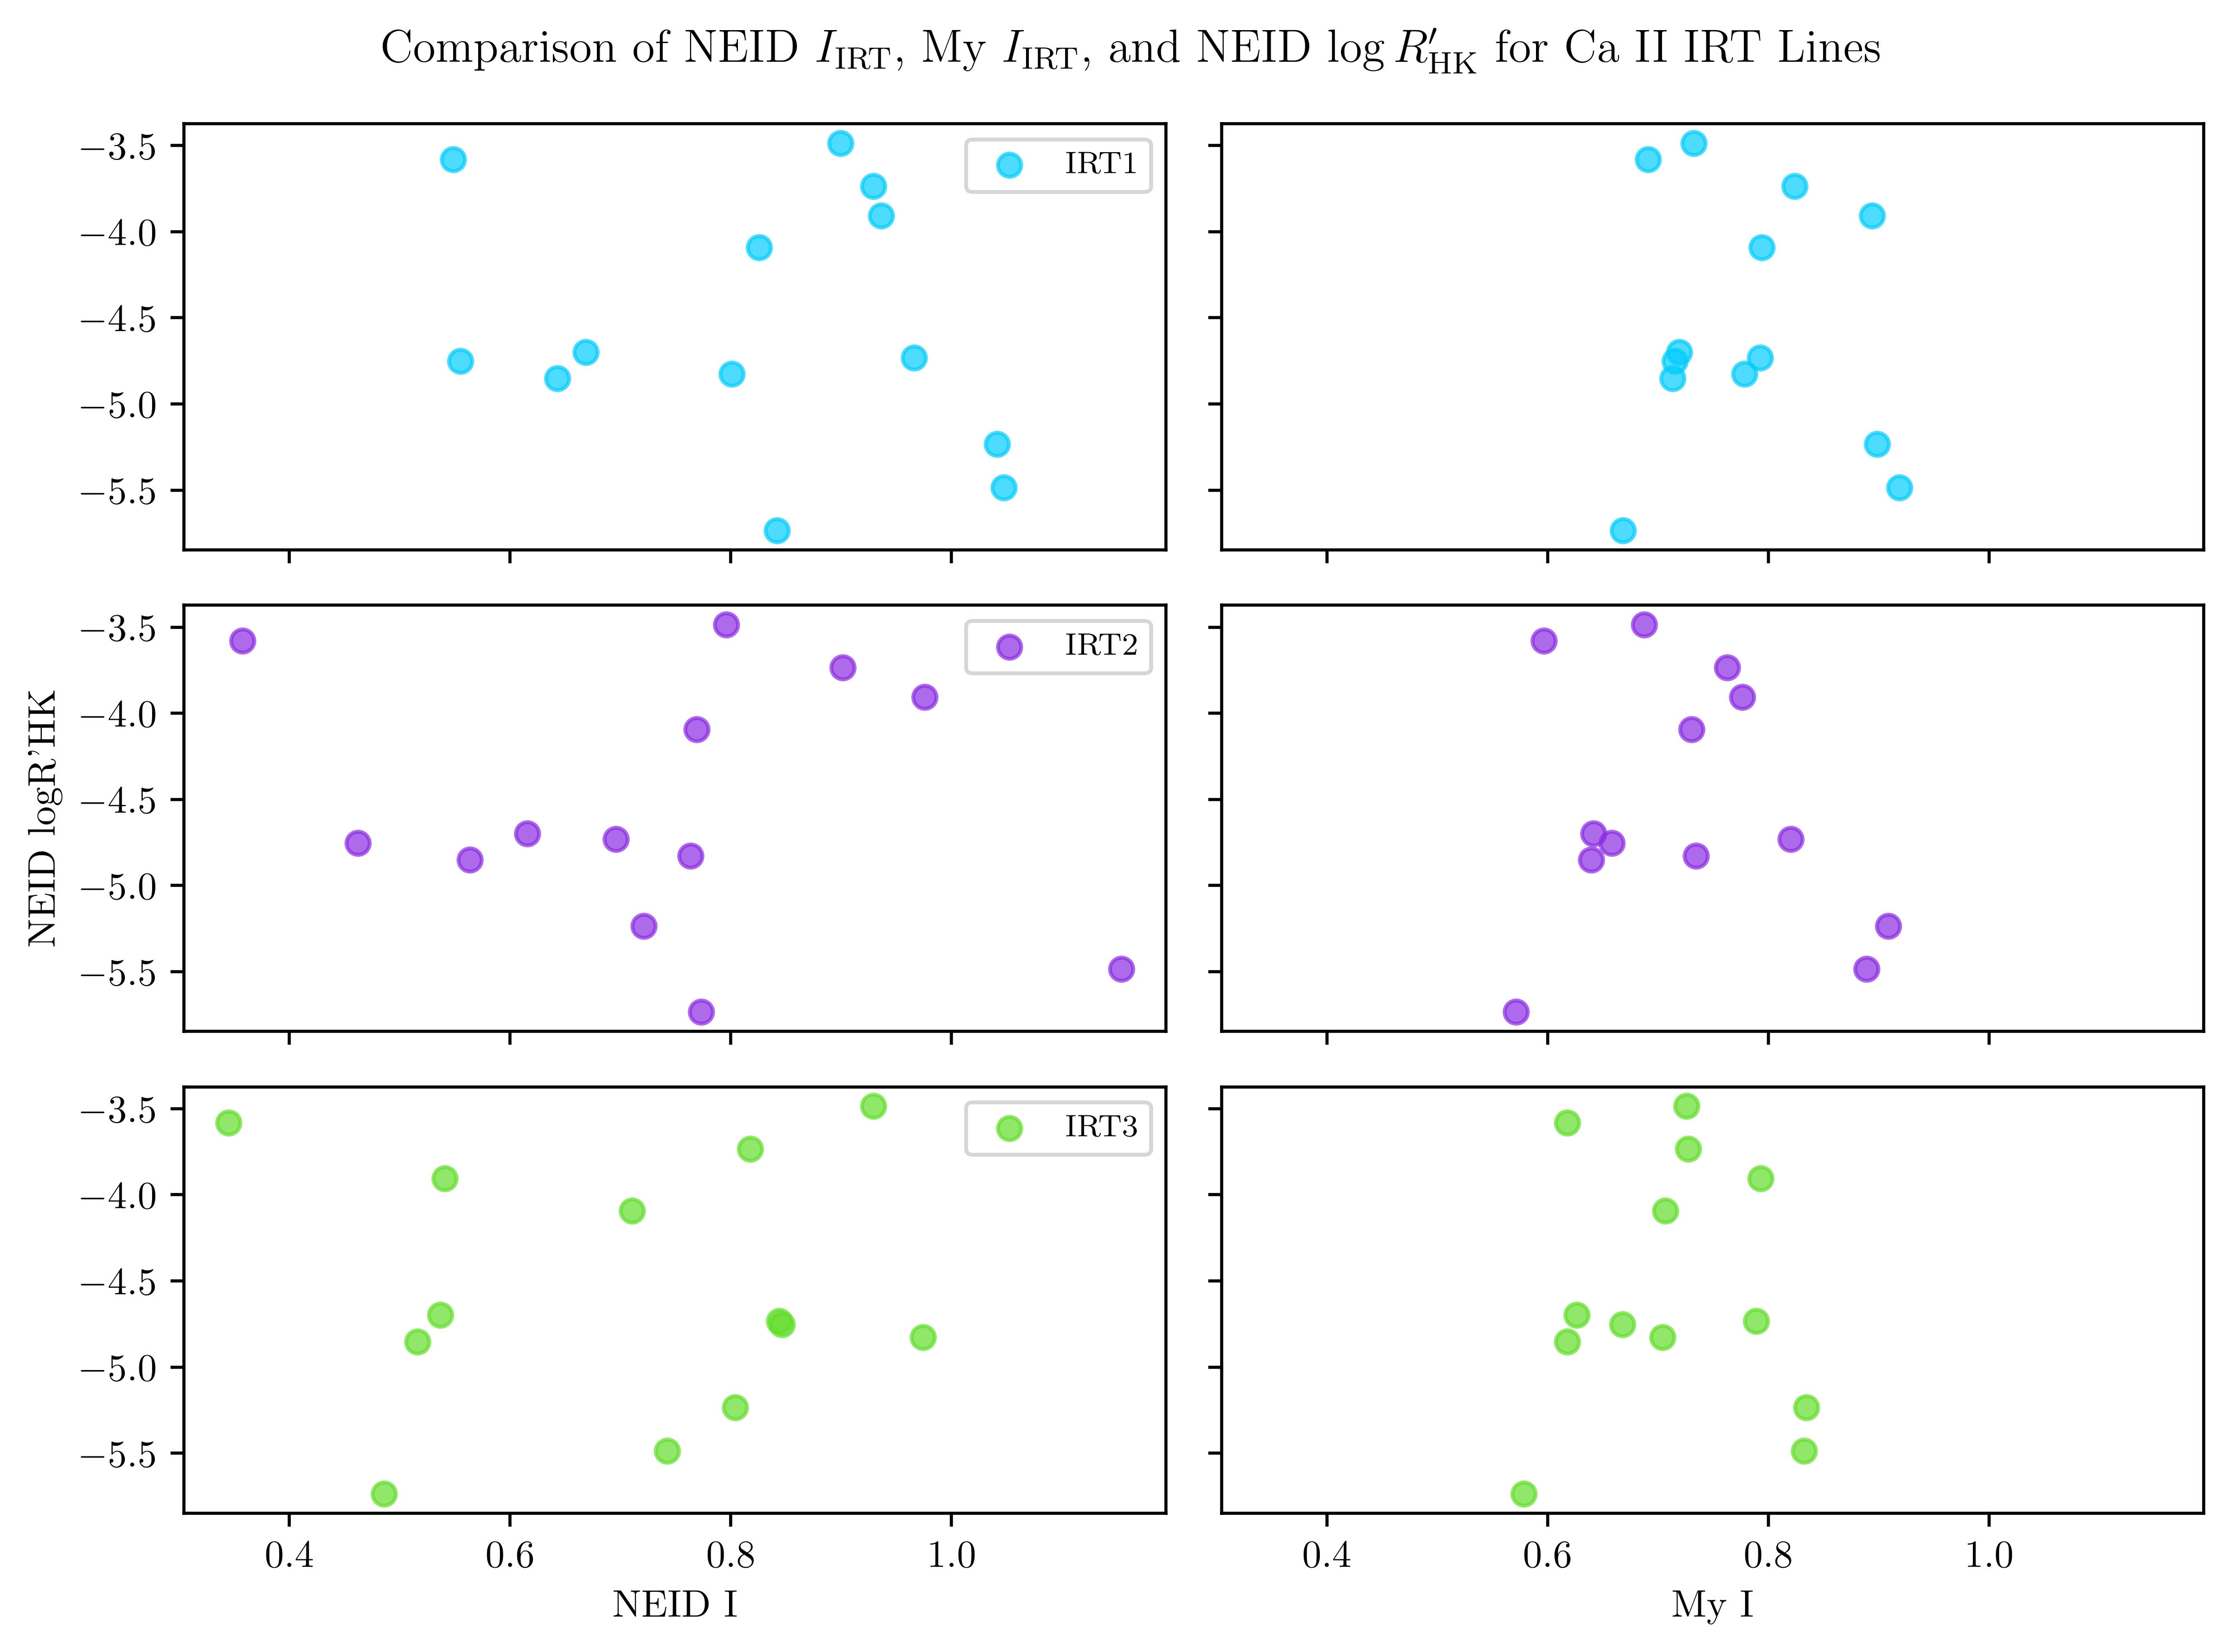

In [119]:
fit1 = np.polyfit(compare_df["NEID I1"], compare_df["NEID logR'HK"], 1)
fit2 = np.polyfit(compare_df["NEID I2"], compare_df["NEID logR'HK"], 1)
fit3 = np.polyfit(compare_df["NEID I3"], compare_df["NEID logR'HK"], 1)
fit4 = np.polyfit(compare_df["My I1"], compare_df["NEID logR'HK"], 1)
fit5 = np.polyfit(compare_df["My I2"], compare_df["NEID logR'HK"], 1)
fit6 = np.polyfit(compare_df["My I3"], compare_df["NEID logR'HK"], 1)

y = compare_df["NEID logR'HK"]

x_columns = {
    "NEID I1": compare_df["NEID I1"],
    "NEID I2": compare_df["NEID I2"],
    "NEID I3": compare_df["NEID I3"],
    "My I1": compare_df["My I1"],
    "My I2": compare_df["My I2"],
    "My I3": compare_df["My I3"]
}

results = []

for name, x in x_columns.items():
    data = pd.DataFrame({"x": x, "y": y}).replace([np.inf, -np.inf], np.nan).dropna()
    x_clean, y_clean = data["x"], data["y"]
    fit = stats.linregress(x_clean, y_clean)
    y_pred = fit.intercept + fit.slope * x_clean

    results.append({
        "Index": name,
        "N": len(data),
        "Slope": fit.slope,
        "Intercept": fit.intercept,
        "R²": fit.rvalue**2,
        "Pearson r": fit.rvalue,
        "p-value": fit.pvalue,
        "RMSE": np.sqrt(np.mean((y_clean - y_pred)**2))
    })

stats_df = pd.DataFrame(results)
print(stats_df.to_string(index=False, float_format=lambda v: f"{v:.4g}"))

fig, ax = plt.subplots(3, 2, figsize=(8, 6), dpi=500, sharex=True, sharey=True)
ax[0, 0].scatter(compare_df["NEID I1"], compare_df["NEID logR'HK"], label="IRT1", color='xkcd:bright sky blue', alpha=0.7)
ax[0, 0].plot(compare_df["NEID I1"], np.polyval(fit1, compare_df["NEID I1"]), color='xkcd:bright sky blue', linestyle='-', label=f'')
ax[1, 0].scatter(compare_df["NEID I2"], compare_df["NEID logR'HK"], label="IRT2", color='blueviolet', alpha=0.7)
ax[1, 0].plot(compare_df["NEID I2"], np.polyval(fit2, compare_df["NEID I2"]), color='blueviolet', linestyle='-', label=f'')
ax[2, 0].scatter(compare_df["NEID I3"], compare_df["NEID logR'HK"], label="IRT3", color='xkcd:toxic green', alpha=0.7)
ax[2, 0].plot(compare_df["NEID I3"], np.polyval(fit3, compare_df["NEID I3"]), color='xkcd:toxic green', linestyle='-', label=f'')

# ax[0, 0].set_title("Comparison of NEID I, My I, and NEID logR'HK for Ca II IRT Lines")
ax[0, 0].legend(fontsize=8)
ax[1, 0].set_ylabel("NEID logR'HK")
ax[1, 0].legend(fontsize=8)
ax[2, 0].set_xlabel("NEID I")
ax[2, 0].legend(fontsize=8)

ax[0, 1].scatter(compare_df["My I1"], compare_df["NEID logR'HK"], label="IRT1", color='xkcd:bright sky blue', alpha=0.7)
ax[1, 1].scatter(compare_df["My I2"], compare_df["NEID logR'HK"], label="IRT2", color='blueviolet', alpha=0.7)
ax[2, 1].scatter(compare_df["My I3"], compare_df["NEID logR'HK"], label="IRT3", color='xkcd:toxic green', alpha=0.7)
ax[0, 1].plot(compare_df["My I1"], fit4[0] * compare_df["My I1"] + fit4[1], color='xkcd:bright sky blue', linestyle='-', label='')
ax[1, 1].plot(compare_df["My I2"], fit5[0] * compare_df["My I2"] + fit5[1], color='blueviolet', linestyle='-', label='')
ax[2, 1].plot(compare_df["My I3"], fit6[0] * compare_df["My I3"] + fit6[1], color='xkcd:toxic green', linestyle='-', label='')

# ax[0, 1].set_title("Comparison of My I and My log_RHK_total for Ca II IRT Lines")
# ax[0, 1].legend()
# ax[1, 1].set_ylabel("NEID logR'HK")
# ax[1, 1].legend()
ax[2, 1].set_xlabel("My I")
# ax[2, 1].legend()

fig.suptitle(r"Comparison of NEID $I_{\rm IRT}$, My $I_{\rm IRT}$, and NEID $\log R'_{\rm HK}$ for Ca II IRT Lines")
plt.tight_layout()
# plt.savefig("/Users/brooklyngustaf/Desktop/Research/plots/Activity Indicators/Ca_II_IRT_I_comparison.png", dpi=500)
plt.show()

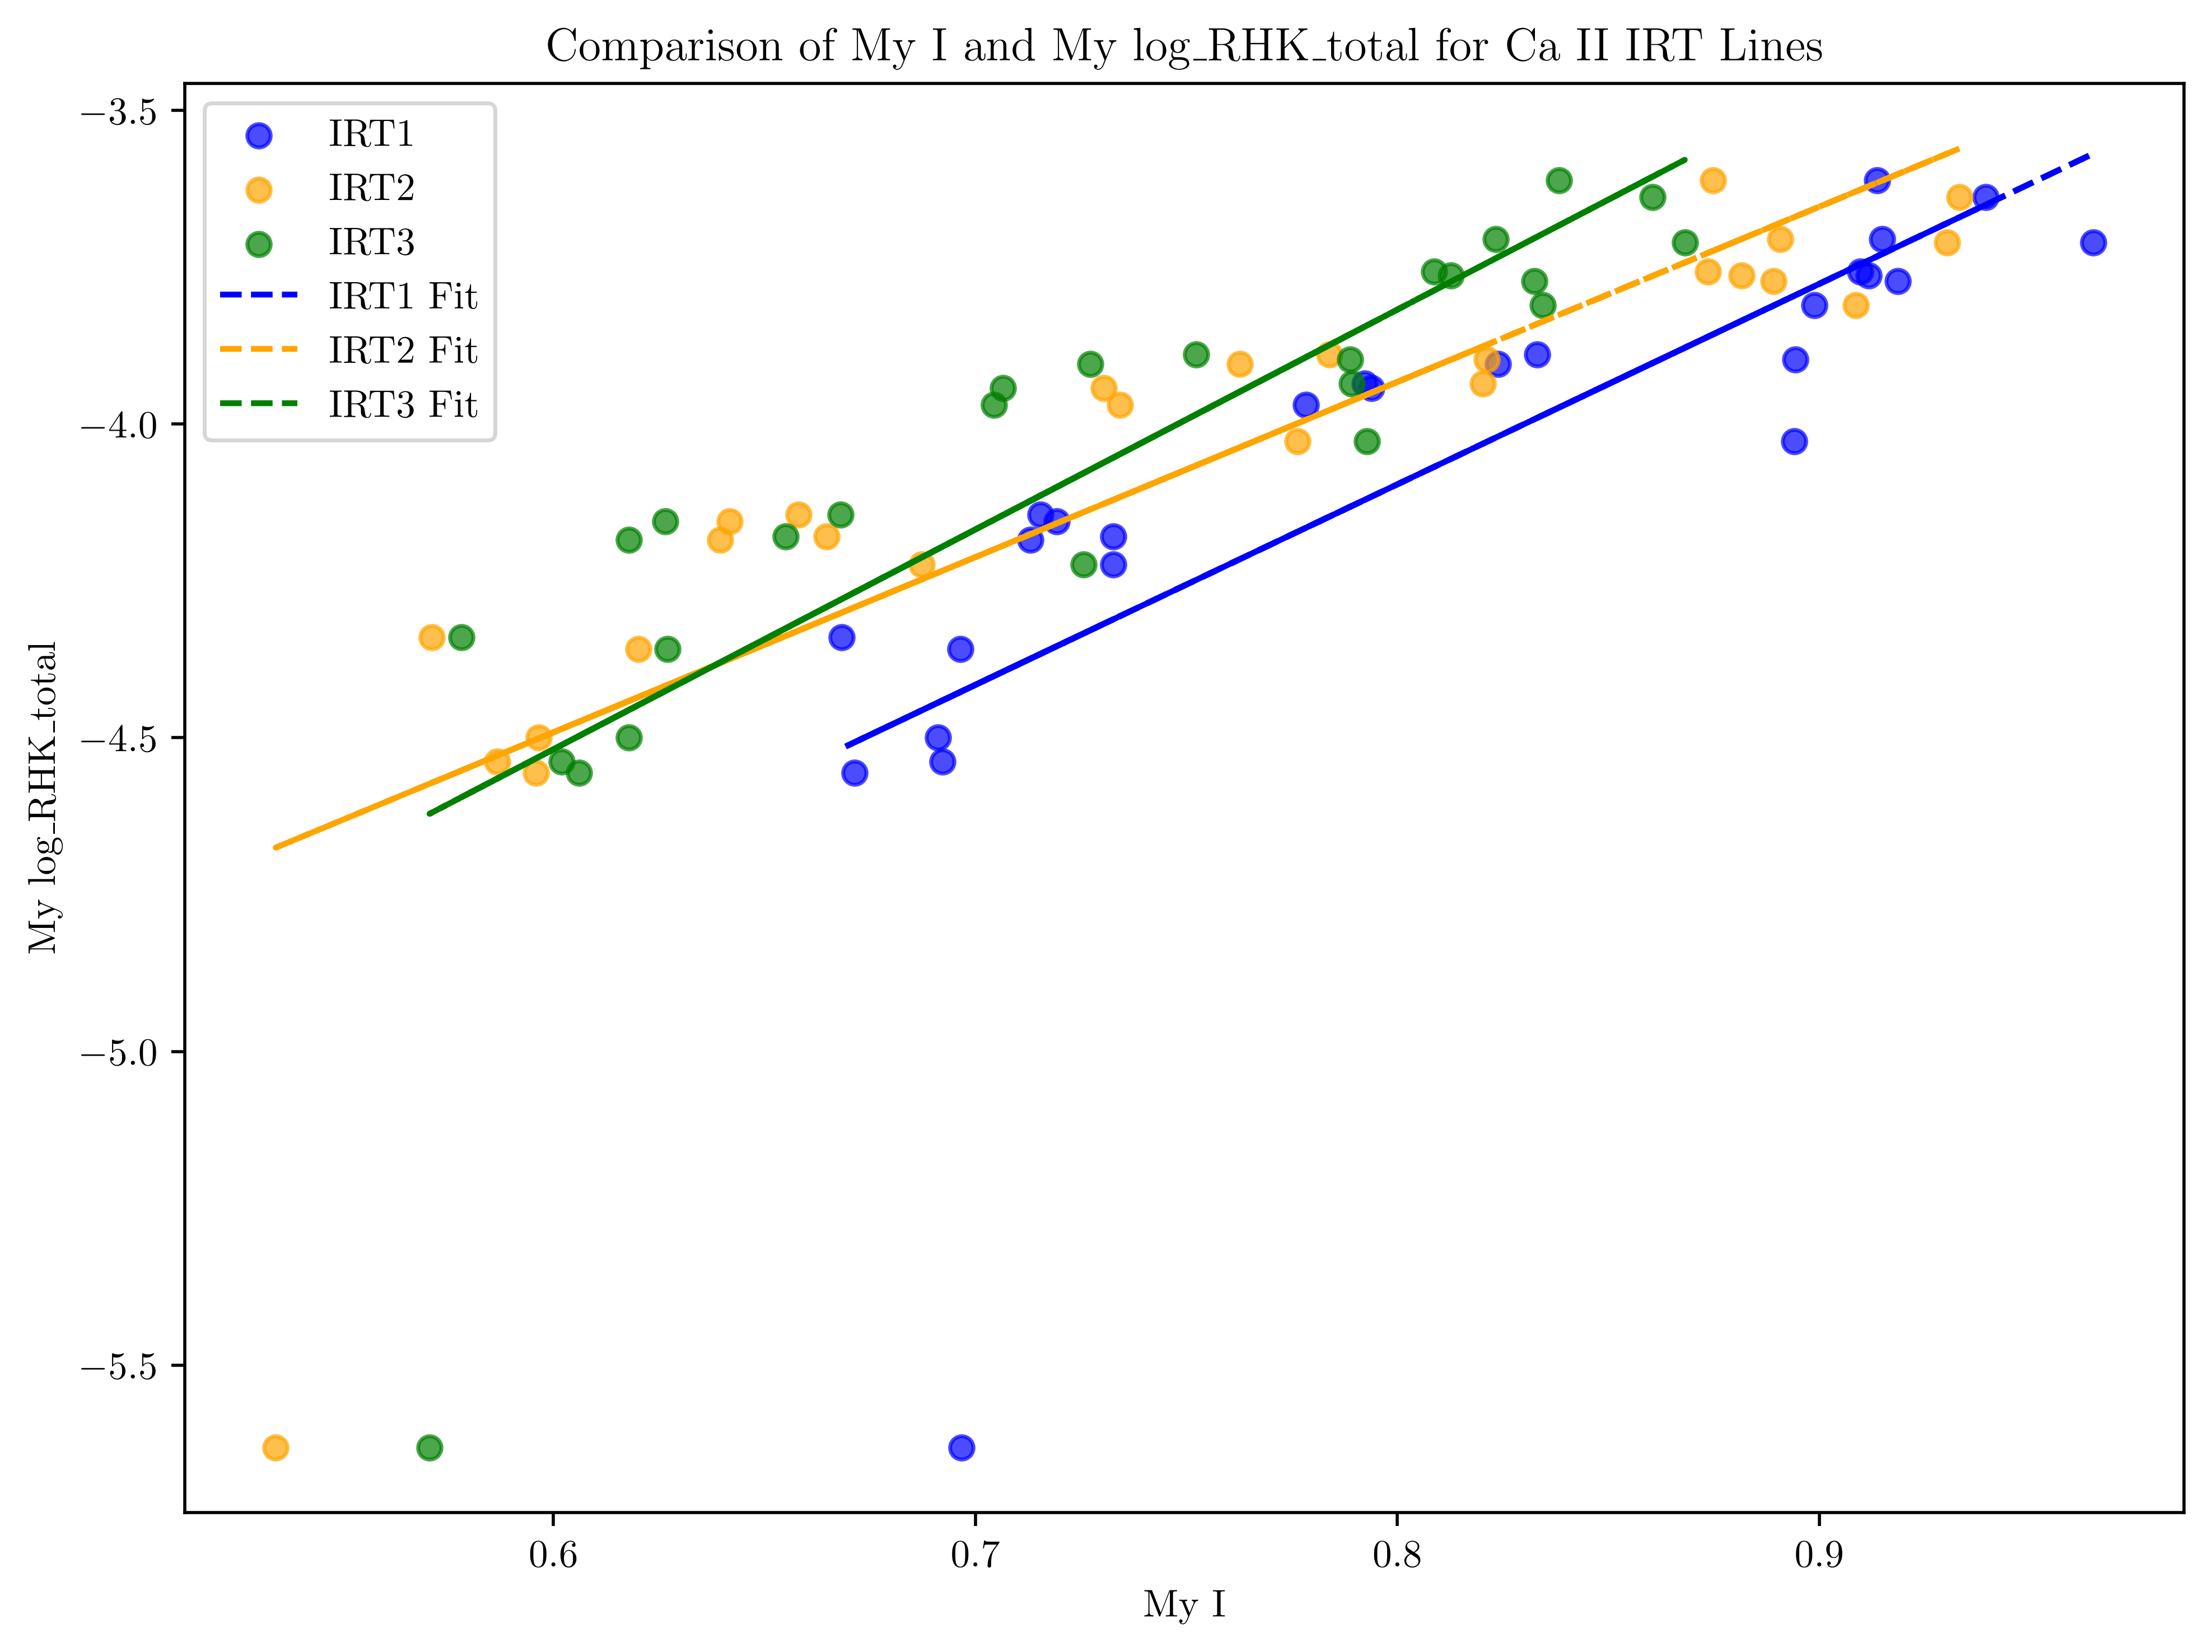

In [74]:
fit1 = np.polyfit(compare_I["My I1"], test["log_RHK_total"], 1)
fit2 = np.polyfit(compare_I["My I2"], test["log_RHK_total"], 1)
fit3 = np.polyfit(compare_I["My I3"], test["log_RHK_total"], 1)

fig, ax = plt.subplots(figsize=(8, 6), dpi=500)
ax.scatter(compare_I["My I1"], test["log_RHK_total"], label="IRT1", color='blue', alpha=0.7)
ax.scatter(compare_I["My I2"], test["log_RHK_total"], label="IRT2", color='orange', alpha=0.7)
ax.scatter(compare_I["My I3"], test["log_RHK_total"], label="IRT3", color='green', alpha=0.7)
ax.plot(compare_I["My I1"], fit1[0] * compare_I["My I1"] + fit1[1], color='blue', linestyle='--', label='IRT1 Fit')
ax.plot(compare_I["My I2"], fit2[0] * compare_I["My I2"] + fit2[1], color='orange', linestyle='--', label='IRT2 Fit')
ax.plot(compare_I["My I3"], fit3[0] * compare_I["My I3"] + fit3[1], color='green', linestyle='--', label='IRT3 Fit')
ax.set_xlabel("My I")
ax.set_ylabel("My log_RHK_total")
ax.set_title("Comparison of My I and My log_RHK_total for Ca II IRT Lines")
ax.legend()
plt.tight_layout()
# plt.savefig("/Users/brooklyngustaf/Desktop/Research/plots/Activity Indicators/Ca_II_IRT_I_comparison.png", dpi=500)
plt.show()

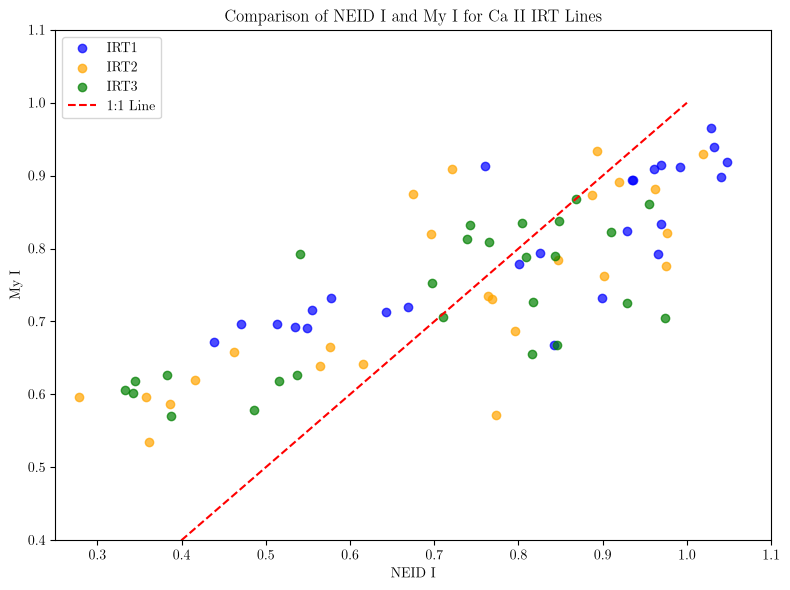

In [79]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(compare_I["NEID I1"], compare_I["My I1"], label="IRT1", color='blue', alpha=0.7)
ax.scatter(compare_I["NEID I2"], compare_I["My I2"], label="IRT2", color='orange', alpha=0.7)
ax.scatter(compare_I["NEID I3"], compare_I["My I3"], label="IRT3", color='green', alpha=0.7)
ax.plot([0, 1], [0, 1], color='red', linestyle='--', label='1:1 Line')
ax.set_xlim(0.25, 1.1)
ax.set_ylim(0.4, 1.1)
ax.set_xlabel("NEID I")
ax.set_ylabel("My I")
ax.set_title("Comparison of NEID I and My I for Ca II IRT Lines")
ax.legend()
plt.tight_layout()
# plt.savefig("/Users/brooklyngustaf/Desktop/Research/plots/Activity Indicators/Ca_II_IRT_I_comparison.png", dpi=500)
plt.show()